# Machine Learning – Midterm Assignment
## Breast Cancer Wisconsin dataset

This notebook covers **Sections 1–10** of the assignment for the **Breast Cancer Wisconsin** dataset (`sklearn.datasets.load_breast_cancer`).
The companion notebook `wine.ipynb` repeats exactly the same steps for the Wine Classification dataset. The two datasets, their models and their results are kept separate.

**Experiment plan for this dataset**

| Part | Runs |
|---|---|
| Classifiers: (5 Decision Tree + 5 KNN + 1 Gaussian NB) settings × 2 representations × 3 seeds | 66 fits |
| K-Means: 2 representations × 3 seeds | 6 fits |
| **Total for this dataset** | **72 fits** (144 over both datasets) |

All repeated work is done with loops and reusable functions. At the end, the notebook writes this dataset's rows into the six shared CSV files in `results/` and its figures into `figures/`.

## 0. Setup

In [1]:
import sys
import platform
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
import sklearn
from IPython.display import display

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, label_binarize
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.cluster import KMeans
from sklearn.feature_selection import f_classif
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, roc_curve, auc,
    classification_report, confusion_matrix,
    adjusted_rand_score, silhouette_score,
)

# ---- fixed settings of the assignment -------------------------------------
DATASET_KEY = "breast_cancer"            # used in experiment IDs and in the 'dataset' column
DATASET_TITLE = "Breast Cancer Wisconsin"
N_CLUSTERS = 2                      # K-Means: fixed to the number of classes
SEEDS = [42, 52, 62]                # training/validation repetitions
TEST_SPLIT_SEED = 42                # the test set is reserved ONCE with this seed
FINAL_SEED = 42                     # predeclared seed whose fitted models are tested
REPRESENTATIONS = ["unscaled", "scaled"]

RESULTS_DIR = Path("results")
FIG_DIR = Path("figures")
RESULTS_DIR.mkdir(exist_ok=True)
FIG_DIR.mkdir(exist_ok=True)

pd.set_option("display.max_rows", 200)
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 220)
pd.set_option("display.precision", 4)

# ---- plotting style ---------------------------------------------------------
CLASS_COLORS = ["#2a78d6", "#eb6834", "#1baf7a"]     # true classes
CLUSTER_COLORS = ["#6250d6", "#eda100", "#e34948"]   # cluster IDs (different on purpose)
CLASS_MARKERS = ["o", "s", "^"]
CLUSTER_MARKERS = ["D", "P", "X"]
DIVERGING = LinearSegmentedColormap.from_list("blue_grey_orange", ["#2a78d6", "#f0efec", "#eb6834"])

plt.rcParams.update({
    "figure.dpi": 100, "savefig.dpi": 150,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e3e2de", "grid.linewidth": 0.8,
    "axes.axisbelow": True, "font.size": 10, "axes.titlesize": 11,
})

def save_fig(fig, name):
    """Save a figure as figures/<dataset>_<name>.png and show it."""
    path = FIG_DIR / f"{DATASET_KEY}_{name}.png"
    fig.savefig(path, bbox_inches="tight")
    plt.show()
    print(f"Saved figure: {path.as_posix()}")

In [2]:
# Package versions used for this run (recorded for reproducibility)
versions = pd.DataFrame({
    "package": ["python", "numpy", "pandas", "scikit-learn", "matplotlib"],
    "version": [platform.python_version(), np.__version__, pd.__version__,
                sklearn.__version__, matplotlib.__version__],
})
print(f"[{DATASET_TITLE}] Package versions used for this run")
display(versions)

[Breast Cancer Wisconsin] Package versions used for this run


,package,version
0,python,3.13.18
1,numpy,2.5.3
2,pandas,3.0.5
3,scikit-learn,1.9.1
4,matplotlib,3.11.2


## 1. Loading the Datasets

### 1.1 Load both datasets from scikit-learn

This notebook loads **Breast Cancer Wisconsin** with `load_breast_cancer`. The second dataset (Wine Classification) is loaded and analysed in `wine.ipynb`, so both datasets are used in the assignment.

In [3]:
data = load_breast_cancer()
print("Loaded:", DATASET_TITLE)
print("Type of the returned object:", type(data).__name__)

Loaded: Breast Cancer Wisconsin
Type of the returned object: Bunch


### 1.2 Create the data frames

Features `X` and target `y` are kept separate. `X` is a pandas DataFrame with the original feature names and it does **not** contain the target. The original scikit-learn class labels are kept.

In [4]:
X = pd.DataFrame(data.data, columns=list(data.feature_names))
y = pd.Series(data.target, name="target")

CLASS_LABELS = [int(c) for c in np.unique(y)]
TARGET_NAMES = [str(n) for n in data.target_names]

assert "target" not in X.columns
print(f"[{DATASET_TITLE}] First five rows of X:")
display(X.head())

print("Dataset shape (X):", X.shape, "-> samples x features")
print("Target shape (y): ", y.shape)
print("\nFeature names:")
for i, name in enumerate(X.columns, start=1):
    print(f"  {i:2d}. {name}")
print("\nTarget labels:", CLASS_LABELS)
print("Target names: ", TARGET_NAMES)

[Breast Cancer Wisconsin] First five rows of X:


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,radius error,texture error,perimeter error,area error,smoothness error,compactness error,concavity error,concave points error,symmetry error,fractal dimension error,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,122.80,1001.0,0.1184,0.2776,0.3001,0.1471,0.2419,0.0787,1.0950,0.9053,8.589,153.40,0.0064,0.0490,0.0537,0.0159,0.0300,0.0062,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.1189
1,20.57,17.77,132.90,1326.0,0.0847,0.0786,0.0869,0.0702,0.1812,0.0567,0.5435,0.7339,3.398,74.08,0.0052,0.0131,0.0186,0.0134,0.0139,0.0035,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.0890
2,19.69,21.25,130.00,1203.0,0.1096,0.1599,0.1974,0.1279,0.2069,0.0600,0.7456,0.7869,4.585,94.03,0.0062,0.0401,0.0383,0.0206,0.0225,0.0046,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.0876
3,11.42,20.38,77.58,386.1,0.1425,0.2839,0.2414,0.1052,0.2597,0.0974,0.4956,1.1560,3.445,27.23,0.0091,0.0746,0.0566,0.0187,0.0596,0.0092,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.1730
4,20.29,14.34,135.10,1297.0,0.1003,0.1328,0.1980,0.1043,0.1809,0.0588,0.7572,0.7813,5.438,94.44,0.0115,0.0246,0.0569,0.0188,0.0176,0.0051,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.0768


Dataset shape (X): (569, 30) -> samples x features
Target shape (y):  (569,)

Feature names:
   1. mean radius
   2. mean texture
   3. mean perimeter
   4. mean area
   5. mean smoothness
   6. mean compactness
   7. mean concavity
   8. mean concave points
   9. mean symmetry
  10. mean fractal dimension
  11. radius error
  12. texture error
  13. perimeter error
  14. area error
  15. smoothness error
  16. compactness error
  17. concavity error
  18. concave points error
  19. symmetry error
  20. fractal dimension error
  21. worst radius
  22. worst texture
  23. worst perimeter
  24. worst area
  25. worst smoothness
  26. worst compactness
  27. worst concavity
  28. worst concave points
  29. worst symmetry
  30. worst fractal dimension

Target labels: [0, 1]
Target names:  ['malignant', 'benign']


In [5]:
# Dataset overview and class-label mapping
overview = pd.DataFrame({
    "item": ["dataset", "samples", "features", "classes", "feature dtype(s)"],
    "value": [DATASET_TITLE, X.shape[0], X.shape[1], len(CLASS_LABELS),
              ", ".join(sorted({str(t) for t in X.dtypes}))],
})
print(f"[{DATASET_TITLE}] Dataset overview")
display(overview)

class_mapping = pd.DataFrame({
    "class_label": CLASS_LABELS,
    "class_name": TARGET_NAMES,
    "n_samples": [int((y == c).sum()) for c in CLASS_LABELS],
})
class_mapping["percent"] = (100 * class_mapping["n_samples"] / len(y)).round(2)
print(f"[{DATASET_TITLE}] Class-label mapping and number of samples in each class")
display(class_mapping)

[Breast Cancer Wisconsin] Dataset overview


,item,value
0,dataset,Breast Cancer Wisconsin
1,samples,569
2,features,30
3,classes,2
4,feature dtype(s),float64


[Breast Cancer Wisconsin] Class-label mapping and number of samples in each class


,class_label,class_name,n_samples,percent
0,0,malignant,212,37.26
1,1,benign,357,62.74


**Dataset overview.** Breast Cancer Wisconsin has 569 samples and 30 numerical features that describe cell nuclei measured from breast-mass images (10 measurements, each given as a mean, a standard error and a "worst" value). There are two classes.

**Class-label mapping.** The original scikit-learn labels are kept: **0 = malignant** (212 samples, 37.26%) and **1 = benign** (357 samples, 62.74%). Note that the malignant class has label 0, not 1. Whenever malignant-case errors are discussed in this notebook, class 0 is treated as the positive class. The classes are moderately imbalanced, so all splits are stratified and precision, recall and F1 are macro-averaged.

## 2. Dataset Quality Checks

Sections 2 and 3 are **descriptive only**. Nothing calculated here is used to select features, fit preprocessing or remove samples.

### 2.1 Missing values and duplicates

In [6]:
missing_table = pd.DataFrame({
    "column": list(X.columns) + ["target"],
    "missing_count": list(X.isna().sum().values) + [int(y.isna().sum())],
})
print(f"[{DATASET_TITLE}] Missing-value count for every column")
display(missing_table)

n_missing_total = int(missing_table["missing_count"].sum())
n_dup_features = int(X.duplicated().sum())
n_dup_with_target = int(pd.concat([X, y], axis=1).duplicated().sum())

print("Total missing values:", n_missing_total)
print("Duplicate rows (features only):", n_dup_features)
print("Duplicate rows (features + target):", n_dup_with_target)
print()
print("=> " + ("No missing values are present." if n_missing_total == 0
              else "Missing values ARE present; they are handled with training-only imputation in Section 5."))
print("=> " + ("No duplicate rows are present." if n_dup_features == 0
              else f"{n_dup_features} duplicate row(s) are present (reported, not removed)."))

[Breast Cancer Wisconsin] Missing-value count for every column


,column,missing_count
0,mean radius,0
1,mean texture,0
2,mean perimeter,0
3,mean area,0
4,mean smoothness,0
5,mean compactness,0
6,mean concavity,0
7,mean concave points,0
8,mean symmetry,0
9,mean fractal dimension,0


Total missing values: 0
Duplicate rows (features only): 0
Duplicate rows (features + target): 0

=> No missing values are present.
=> No duplicate rows are present.


**Result.** No missing values are present in any of the 30 feature columns or in the target, and there are no duplicate rows. Nothing is filled or removed, and no artificial missing values are created.

### 2.2 Potential outliers

Potential outliers are flagged with the IQR rule: a value is flagged when it is below `Q1 − 1.5·IQR` or above `Q3 + 1.5·IQR`. The values are only counted here; **no observation is deleted or clipped**.

In [7]:
q1 = X.quantile(0.25)
q3 = X.quantile(0.75)
iqr = q3 - q1
lower_fence = q1 - 1.5 * iqr
upper_fence = q3 + 1.5 * iqr

outlier_table = pd.DataFrame({
    "Q1": q1, "Q3": q3, "IQR": iqr,
    "lower_fence": lower_fence, "upper_fence": upper_fence,
    "n_below": (X < lower_fence).sum(),
    "n_above": (X > upper_fence).sum(),
})
outlier_table["n_outliers"] = outlier_table["n_below"] + outlier_table["n_above"]
outlier_table["percent_of_rows"] = (100 * outlier_table["n_outliers"] / len(X)).round(2)
print(f"[{DATASET_TITLE}] Potential outliers per feature (IQR rule, full dataset, descriptive only)")
display(outlier_table.sort_values("n_outliers", ascending=False))

rows_with_outlier = int(((X < lower_fence) | (X > upper_fence)).any(axis=1).sum())
print(f"Rows with at least one flagged value: {rows_with_outlier} of {len(X)} "
      f"({100 * rows_with_outlier / len(X):.1f}%)")
print(f"Flagged values below the lower fence: {int(outlier_table['n_below'].sum())}, "
      f"above the upper fence: {int(outlier_table['n_above'].sum())}")

[Breast Cancer Wisconsin] Potential outliers per feature (IQR rule, full dataset, descriptive only)


,Q1,Q3,IQR,lower_fence,upper_fence,n_below,n_above,n_outliers,percent_of_rows
area error,17.8500,45.1900,27.3400,-23.1600,86.2000,0,65,65,11.42
radius error,0.2324,0.4789,0.2465,-0.1374,0.8487,0,38,38,6.68
perimeter error,1.6060,3.3570,1.7510,-1.0205,5.9835,0,38,38,6.68
worst area,515.3000,1084.0000,568.7000,-337.7500,1937.0500,0,35,35,6.15
smoothness error,0.0052,0.0081,0.0030,0.0007,0.0126,0,30,30,5.27
fractal dimension error,0.0022,0.0046,0.0023,-0.0012,0.0080,0,28,28,4.92
compactness error,0.0131,0.0324,0.0194,-0.0160,0.0615,0,28,28,4.92
symmetry error,0.0152,0.0235,0.0083,0.0027,0.0360,0,27,27,4.75
mean area,420.3000,782.7000,362.4000,-123.3000,1326.3000,0,25,25,4.39
worst fractal dimension,0.0715,0.0921,0.0206,0.0405,0.1230,0,24,24,4.22


Rows with at least one flagged value: 171 of 569 (30.1%)
Flagged values below the lower fence: 3, above the upper fence: 605


**Discussion.** The IQR rule flags 608 values (605 above the upper fence and only 3 below the lower fence), and 171 of 569 rows (30.1%) contain at least one flagged value. The most affected features are `area error` (65 values, 11.4% of the rows), `radius error` and `perimeter error` (38 each) and `worst area` (35). Only `worst concave points` has no flagged value. Because almost all flagged values are on the high side, they look like the long right tail of skewed measurements (large tumours) rather than recording errors.

How unusually large or small values could affect the algorithms:

* **KNN** and **K-Means** use Euclidean distance. One very large value in one feature can dominate the distance between two samples. K-Means centroids are means, so a few extreme points can pull a centroid towards them.
* **StandardScaler** uses the mean and the standard deviation, and both are sensitive to extreme values. Scaling changes the units but does not remove the outliers (see Section 5.3).
* **Decision Trees** split with thresholds, so only the order of the values matters; extreme values have little effect.
* **Gaussian Naive Bayes** assumes a normal distribution for each feature inside each class. Skewed features with extreme values make the estimated means and variances less representative.

The flagged values are only reported. No observation is deleted or clipped.

### 2.3 Data types

In [8]:
dtype_table = pd.DataFrame({"feature": X.columns, "dtype": [str(t) for t in X.dtypes]})
print(f"[{DATASET_TITLE}] dtype of every feature")
display(dtype_table)

n_numeric = X.select_dtypes(include="number").shape[1]
n_categorical = X.shape[1] - n_numeric
print("Numerical features:  ", n_numeric)
print("Categorical features:", n_categorical)
print("Target dtype:", y.dtype)

[Breast Cancer Wisconsin] dtype of every feature


,feature,dtype
0,mean radius,float64
1,mean texture,float64
2,mean perimeter,float64
3,mean area,float64
4,mean smoothness,float64
5,mean compactness,float64
6,mean concavity,float64
7,mean concave points,float64
8,mean symmetry,float64
9,mean fractal dimension,float64


Numerical features:   30
Categorical features: 0
Target dtype: int64


**Result.** All 30 features are `float64`: 30 numerical features and 0 categorical features. The target is an integer label. No encoding is needed.

**Data-quality concerns (reported, not changed):**
* many features are strongly right-skewed with many high values (Section 2.2);
* the features are on very different scales, from `worst area` (up to 4254) to `fractal dimension error` (below 0.03);
* some concavity features have a minimum of exactly 0 (`mean concavity`, `mean concave points`, and their error/worst versions); these are valid measurements, not missing values;
* the radius, perimeter and area features carry almost the same information (Section 3.2).

## 3. Exploratory Data Analysis (EDA)

### 3.1 Descriptive statistics

In [9]:
desc = pd.DataFrame({
    "mean": X.mean(),
    "median": X.median(),
    "min": X.min(),
    "max": X.max(),
    "std": X.std(ddof=1),
    "Q1": X.quantile(0.25),
    "Q3": X.quantile(0.75),
})
print(f"[{DATASET_TITLE}] Descriptive statistics for every feature (full dataset, descriptive only)")
display(desc)

[Breast Cancer Wisconsin] Descriptive statistics for every feature (full dataset, descriptive only)


,mean,median,min,max,std,Q1,Q3
mean radius,14.1273,13.3700,6.9810,28.1100,3.5240,11.7000,15.7800
mean texture,19.2896,18.8400,9.7100,39.2800,4.3010,16.1700,21.8000
mean perimeter,91.9690,86.2400,43.7900,188.5000,24.2990,75.1700,104.1000
mean area,654.8891,551.1000,143.5000,2501.0000,351.9141,420.3000,782.7000
mean smoothness,0.0964,0.0959,0.0526,0.1634,0.0141,0.0864,0.1053
mean compactness,0.1043,0.0926,0.0194,0.3454,0.0528,0.0649,0.1304
mean concavity,0.0888,0.0615,0.0000,0.4268,0.0797,0.0296,0.1307
mean concave points,0.0489,0.0335,0.0000,0.2012,0.0388,0.0203,0.0740
mean symmetry,0.1812,0.1792,0.1060,0.3040,0.0274,0.1619,0.1957
mean fractal dimension,0.0628,0.0615,0.0500,0.0974,0.0071,0.0577,0.0661


**Comment.** The features have very different magnitudes: `mean area` has mean 654.9 and standard deviation 351.9, while `mean smoothness` has mean 0.096 and standard deviation 0.014. For many features the mean is clearly larger than the median (for example `area error`: mean 40.34, median 24.53, maximum 542.2), which shows right-skewed distributions.

### 3.2 Class distribution and correlations

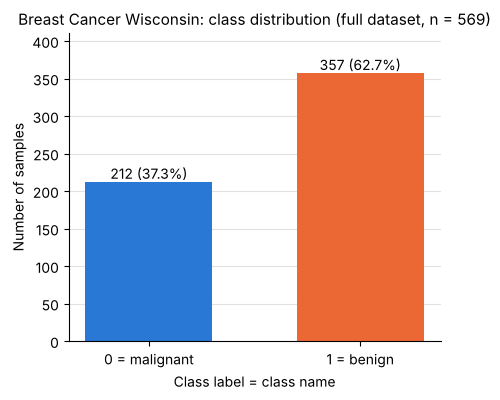

Saved figure: figures/breast_cancer_class_distribution.png


In [10]:
# Figure: class distribution
fig, ax = plt.subplots(figsize=(1.6 + 1.6 * len(CLASS_LABELS), 4))
counts = [int((y == c).sum()) for c in CLASS_LABELS]
tick_labels = [f"{c} = {n}" for c, n in zip(CLASS_LABELS, TARGET_NAMES)]
bars = ax.bar(tick_labels, counts, color=CLASS_COLORS[:len(CLASS_LABELS)], width=0.6)
for b, n in zip(bars, counts):
    ax.text(b.get_x() + b.get_width() / 2, n, f"{n} ({100 * n / len(y):.1f}%)",
            ha="center", va="bottom")
ax.set_xlabel("Class label = class name")
ax.set_ylabel("Number of samples")
ax.set_title(f"{DATASET_TITLE}: class distribution (full dataset, n = {len(y)})")
ax.grid(axis="x", visible=False)
ax.set_ylim(0, max(counts) * 1.15)
save_fig(fig, "class_distribution")

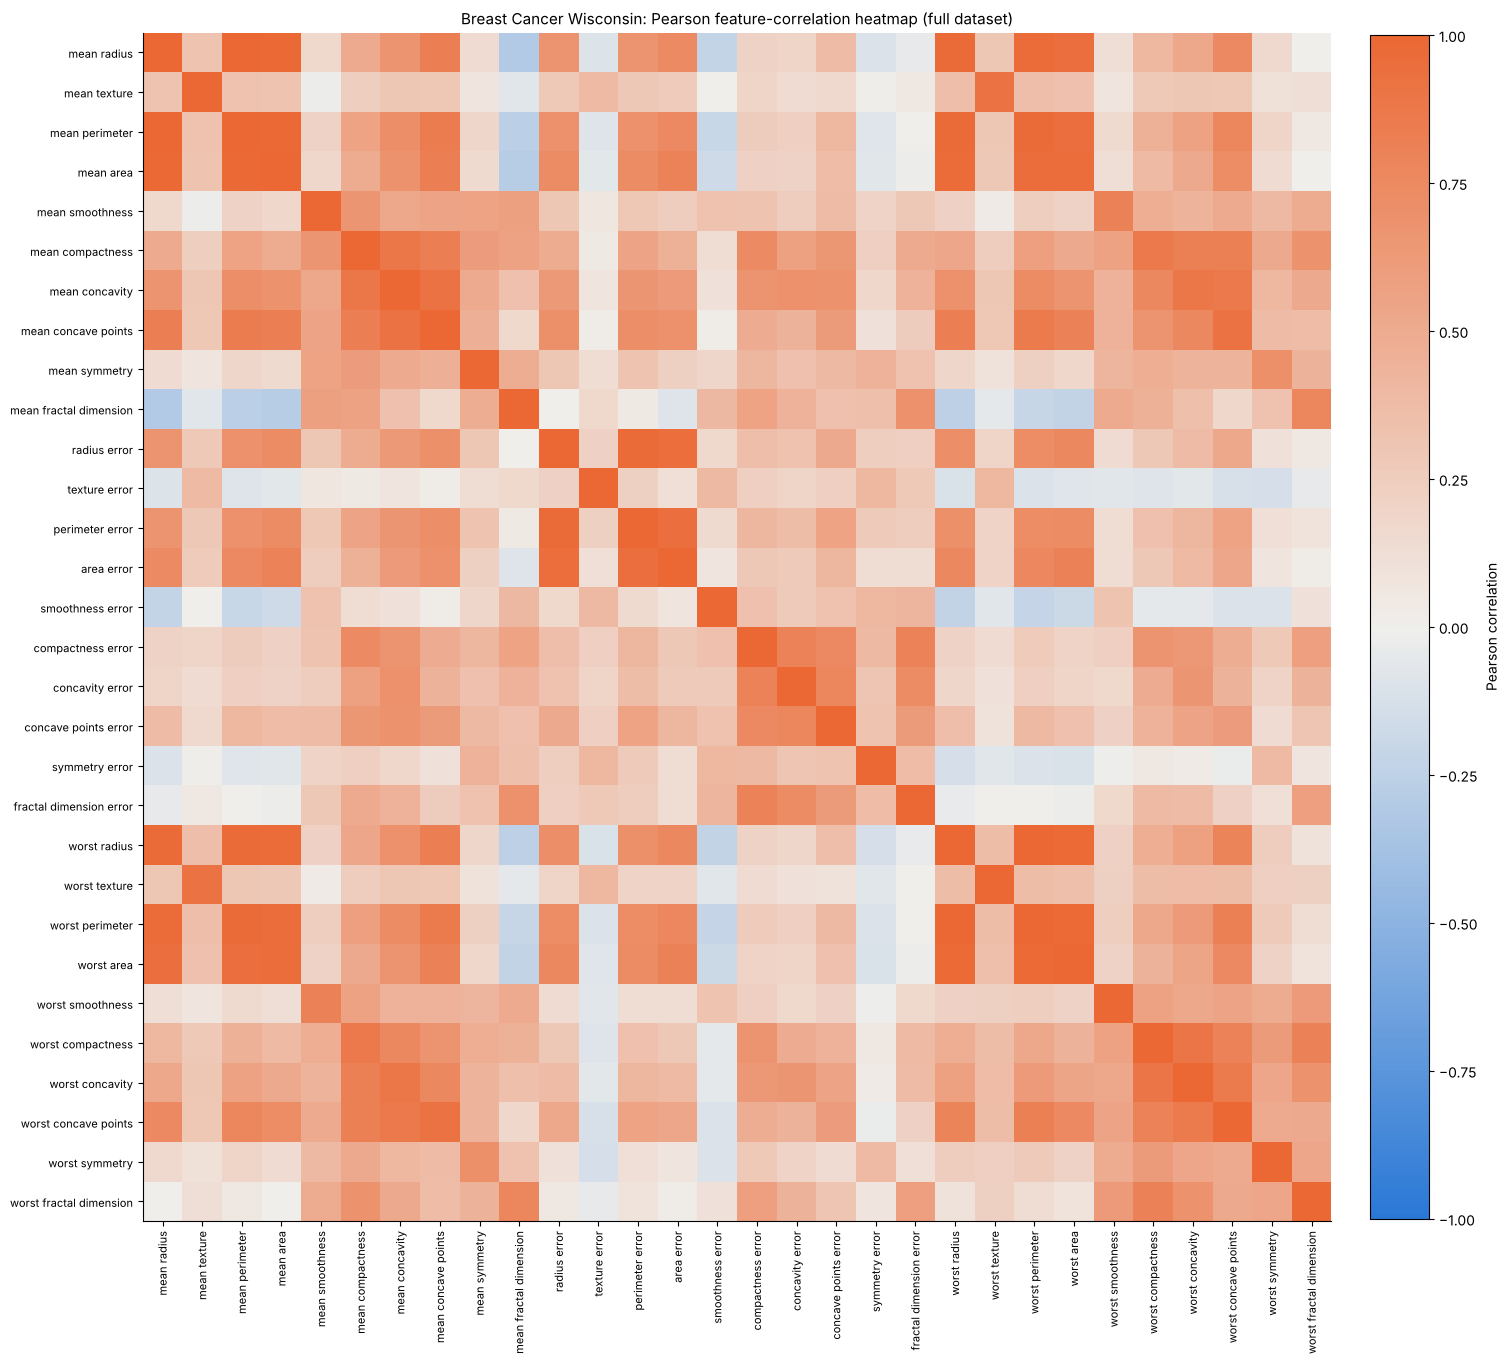

Saved figure: figures/breast_cancer_correlation_heatmap.png


In [11]:
# Figure: Pearson feature-correlation heatmap
corr = X.corr(method="pearson")
n_feat = corr.shape[0]
size = max(7, 0.42 * n_feat + 3)
fig, ax = plt.subplots(figsize=(size + 1, size))
im = ax.imshow(corr.values, cmap=DIVERGING, vmin=-1, vmax=1)
ax.set_xticks(range(n_feat), corr.columns, rotation=90, fontsize=8)
ax.set_yticks(range(n_feat), corr.index, fontsize=8)
ax.grid(False)
if n_feat <= 15:   # annotate only when the cells are large enough to read
    for i in range(n_feat):
        for j in range(n_feat):
            ax.text(j, i, f"{corr.values[i, j]:.2f}", ha="center", va="center", fontsize=7)
cbar = fig.colorbar(im, ax=ax, fraction=0.046, pad=0.03)
cbar.set_label("Pearson correlation")
ax.set_title(f"{DATASET_TITLE}: Pearson feature-correlation heatmap (full dataset)")
save_fig(fig, "correlation_heatmap")

In [12]:
# Three strongest unique feature pairs by absolute correlation
# (upper triangle only -> the diagonal and the mirrored pairs are excluded)
upper = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1))
pairs = upper.stack().dropna().rename("pearson_r").reset_index()
pairs.columns = ["feature_1", "feature_2", "pearson_r"]
pairs["abs_r"] = pairs["pearson_r"].abs()
top3_pairs = pairs.sort_values("abs_r", ascending=False).head(3).reset_index(drop=True)
print(f"[{DATASET_TITLE}] Unique feature pairs checked: {len(pairs)}")
print("Three strongest unique pairs by |Pearson r|:")
display(top3_pairs)

[Breast Cancer Wisconsin] Unique feature pairs checked: 435
Three strongest unique pairs by |Pearson r|:


,feature_1,feature_2,pearson_r,abs_r
0,mean radius,mean perimeter,0.9979,0.9979
1,worst radius,worst perimeter,0.9937,0.9937
2,mean radius,mean area,0.9874,0.9874


**Class distribution.** 357 benign (62.7%) and 212 malignant (37.3%) samples, a ratio of about 1.7 : 1. The imbalance is moderate, which is why stratified splitting and macro-averaged metrics are used.

**Three strongest unique feature pairs (|Pearson r|):**

| Rank | Pair | r |
|---|---|---|
| 1 | `mean radius` – `mean perimeter` | 0.9979 |
| 2 | `worst radius` – `worst perimeter` | 0.9937 |
| 3 | `mean radius` – `mean area` | 0.9874 |

All three pairs are almost perfectly linear and all describe the **size** of the nucleus: perimeter grows in proportion to the radius and area grows with the squared radius. The heatmap shows the same thing as dark blocks between the radius, perimeter and area columns, also across their mean and worst versions. This means that the dataset contains redundant information: in distance-based methods (KNN, K-Means) "size" is counted several times, and the independence assumption of Gaussian Naive Bayes does not hold for these features. As required, this is only described here: no feature is removed and all model experiments use all 30 original features.

### 3.3 Boxplots

Each feature has its own panel and its own y-axis because the features have very different ranges. The features are grouped into several figures to keep them readable.

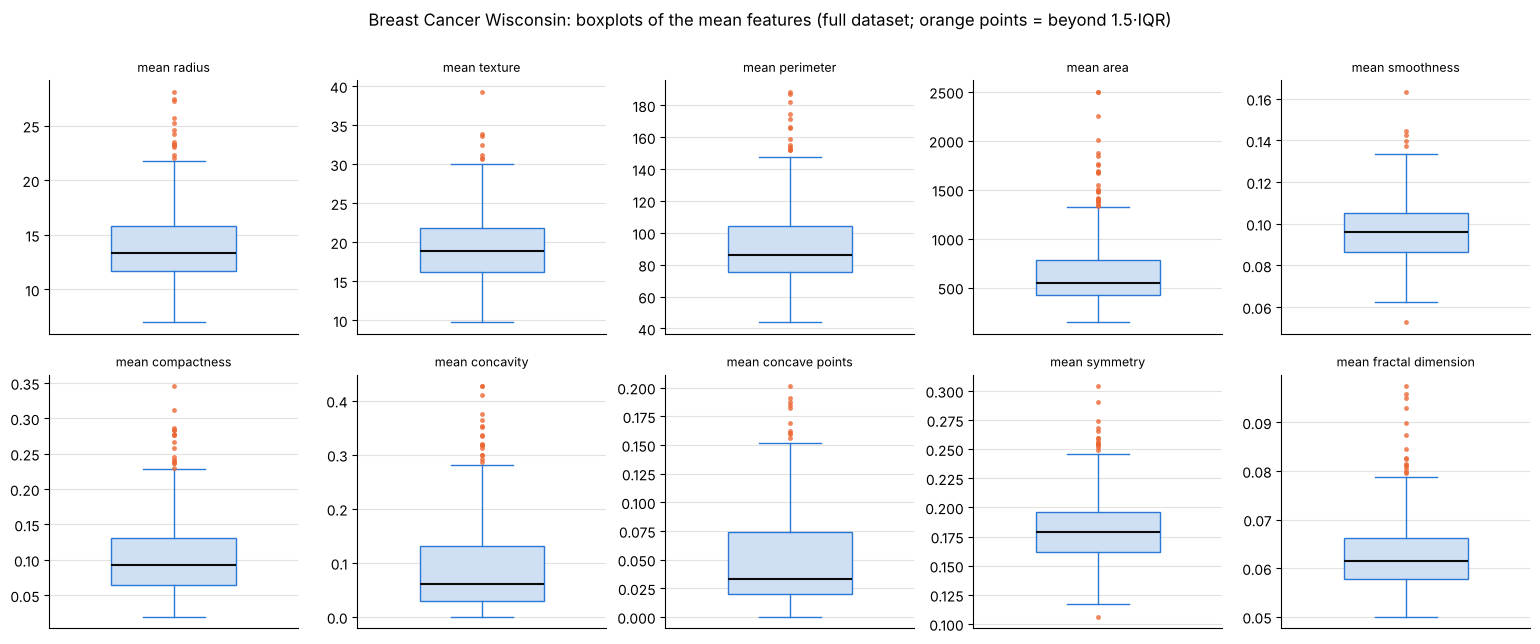

Saved figure: figures/breast_cancer_boxplots_mean.png


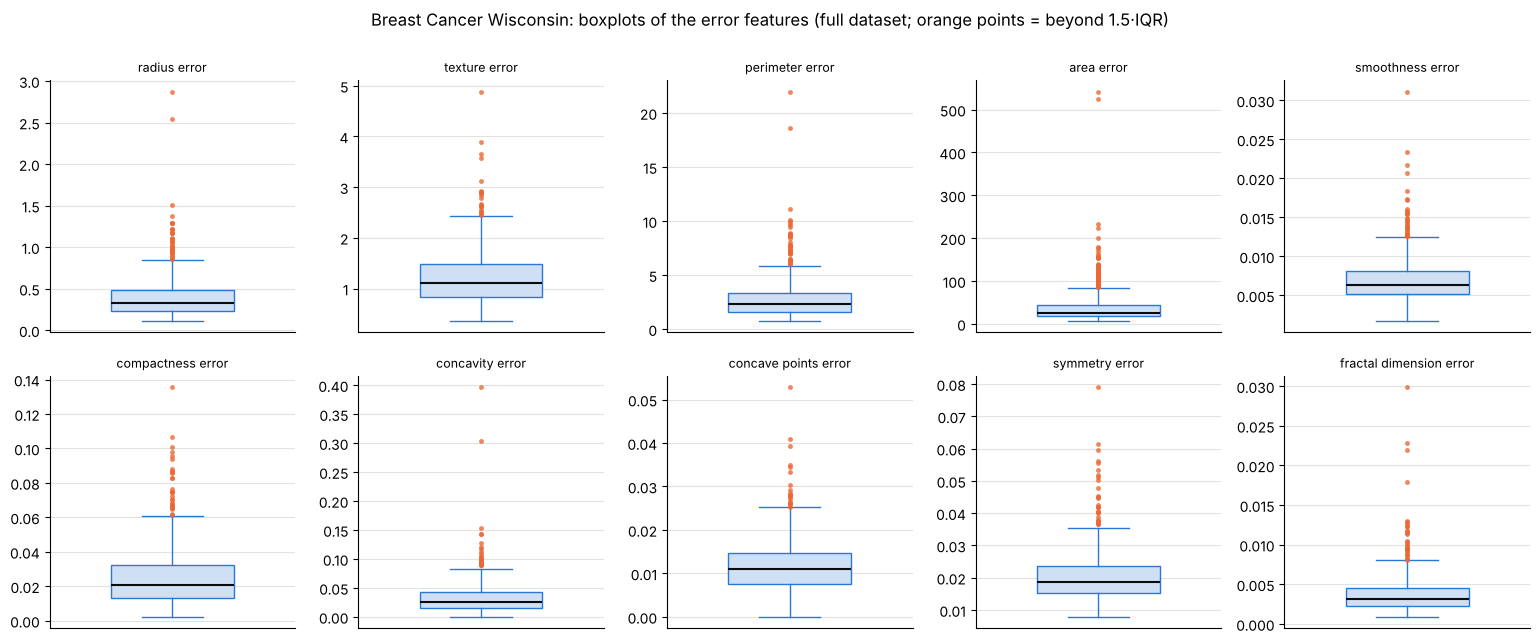

Saved figure: figures/breast_cancer_boxplots_error.png


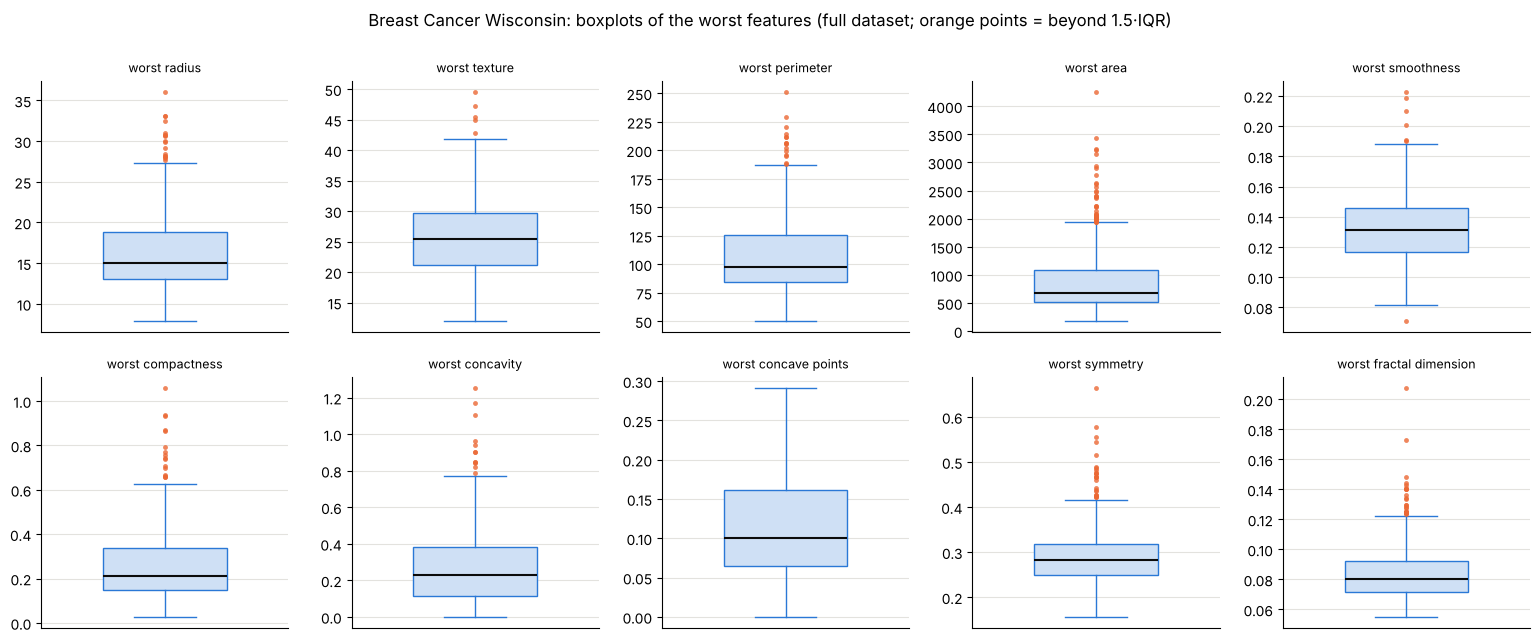

Saved figure: figures/breast_cancer_boxplots_worst.png


In [13]:
BOXPLOT_GROUPS = {"mean features": (0, 10), "error features": (10, 20), "worst features": (20, 30)}

for group_name, (start, stop) in BOXPLOT_GROUPS.items():
    feats = list(X.columns[start:stop])
    n_cols = 5 if len(feats) > 8 else 4
    n_rows = int(np.ceil(len(feats) / n_cols))
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(3.1 * n_cols, 3.2 * n_rows))
    axes = np.atleast_1d(axes).ravel()
    for ax, feat in zip(axes, feats):
        ax.boxplot(X[feat], widths=0.5, patch_artist=True,
                   boxprops=dict(facecolor="#cfe0f5", edgecolor="#2a78d6"),
                   medianprops=dict(color="#0b0b0b", linewidth=1.5),
                   whiskerprops=dict(color="#2a78d6"), capprops=dict(color="#2a78d6"),
                   flierprops=dict(marker="o", markersize=3.5, markerfacecolor="#eb6834",
                                   markeredgecolor="none", alpha=0.8))
        ax.set_title(feat, fontsize=9)
        ax.set_xticks([])
        ax.grid(axis="x", visible=False)
    for ax in axes[len(feats):]:
        ax.set_visible(False)
    fig.suptitle(f"{DATASET_TITLE}: boxplots of the {group_name} (full dataset; orange points = beyond 1.5·IQR)",
                 y=1.0)
    fig.tight_layout()
    save_fig(fig, f"boxplots_{group_name.split()[0].replace('-', '_').lower()}")

**Observations.**

1. **Feature ranges differ by several orders of magnitude.** `mean area` ranges from 143.5 to 2501 and `worst area` from 185.2 to 4254, while `mean smoothness` lies between 0.05 and 0.16 and `fractal dimension error` stays below 0.03. Without scaling, the area features would dominate any Euclidean distance.
2. **Outliers are almost only on the upper side, and the error features are the most skewed.** `area error` has a median of 24.5 but a maximum of 542.2 (about 22 times the median), with two points above 500 far from all the others. `radius error` and `perimeter error` show the same pattern.
3. **A few features are well behaved.** `worst concave points` has no point beyond the whiskers, and `mean smoothness` has only 6 flagged values, on both sides.

## 4. Splitting the Datasets

### 4.1 Fix the test set and repeat the training/validation split

* The 20% test set is reserved **once** with `test_size=0.20`, `stratify=y`, `random_state=42`. Its row indices never change.
* For each seed in `[42, 52, 62]` the remaining 80% is split into training and validation with `test_size=0.125`, stratified, `random_state=seed`. Because 0.125 × 0.80 = 0.10, this gives about 70% / 10% / 20%.
* `train_test_split` keeps the original pandas row indices, so every subset can be traced back to the original rows.

In [14]:
# 1) Reserve the fixed test set ONCE
X_trainval, X_test, y_trainval, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=TEST_SPLIT_SEED)

# 2) Repeat the training/validation split for each seed
splits = {}
for seed in SEEDS:
    X_tr, X_va, y_tr, y_va = train_test_split(
        X_trainval, y_trainval, test_size=0.125, stratify=y_trainval, random_state=seed)
    splits[seed] = {"X_train": X_tr, "X_val": X_va, "y_train": y_tr, "y_val": y_va}

print(f"[{DATASET_TITLE}] Fixed test set: X_test {X_test.shape}, y_test {y_test.shape}")
for seed in SEEDS:
    s = splits[seed]
    print(f"seed {seed}: X_train {s['X_train'].shape}, X_val {s['X_val'].shape}, "
          f"y_train {s['y_train'].shape}, y_val {s['y_val'].shape}")

[Breast Cancer Wisconsin] Fixed test set: X_test (114, 30), y_test (114,)
seed 42: X_train (398, 30), X_val (57, 30), y_train (398,), y_val (57,)
seed 52: X_train (398, 30), X_val (57, 30), y_train (398,), y_val (57,)
seed 62: X_train (398, 30), X_val (57, 30), y_train (398,), y_val (57,)


### 4.2 Verify the split

In [15]:
def subset_row(seed, subset, y_part):
    row = {"dataset": DATASET_KEY, "seed": seed, "subset": subset,
           "n_samples": len(y_part),
           "percent_of_full": round(100 * len(y_part) / len(y), 2)}
    for c, name in zip(CLASS_LABELS, TARGET_NAMES):
        col = f"n_class_{c}" if name == f"class_{c}" else f"n_class_{c}_{name}"
        row[col] = int((y_part == c).sum())
    return row

split_rows = []
for seed in SEEDS:
    split_rows.append(subset_row(seed, "train", splits[seed]["y_train"]))
    split_rows.append(subset_row(seed, "validation", splits[seed]["y_val"]))
    split_rows.append(subset_row(seed, "test", y_test))
split_summary = pd.DataFrame(split_rows)
print(f"[{DATASET_TITLE}] Split summary: 3 subsets x 3 seeds = {len(split_summary)} rows")
display(split_summary)

[Breast Cancer Wisconsin] Split summary: 3 subsets x 3 seeds = 9 rows


,dataset,seed,subset,n_samples,percent_of_full,n_class_0_malignant,n_class_1_benign
0,breast_cancer,42,train,398,69.95,149,249
1,breast_cancer,42,validation,57,10.02,21,36
2,breast_cancer,42,test,114,20.04,42,72
3,breast_cancer,52,train,398,69.95,149,249
4,breast_cancer,52,validation,57,10.02,21,36
5,breast_cancer,52,test,114,20.04,42,72
6,breast_cancer,62,train,398,69.95,149,249
7,breast_cancer,62,validation,57,10.02,21,36
8,breast_cancer,62,test,114,20.04,42,72


In [16]:
# Overlap, completeness and fixed-test checks
check_rows = []
test_idx_reference = sorted(X_test.index)
for seed in SEEDS:
    tr = set(splits[seed]["X_train"].index)
    va = set(splits[seed]["X_val"].index)
    te = set(X_test.index)
    # labels must carry the same indices as the features
    assert list(splits[seed]["X_train"].index) == list(splits[seed]["y_train"].index)
    assert list(splits[seed]["X_val"].index) == list(splits[seed]["y_val"].index)
    # the rows that are neither training nor validation in this repetition:
    left_out = sorted(set(X.index) - tr - va)
    check_rows.append({
        "seed": seed,
        "train ∩ val": len(tr & va),
        "train ∩ test": len(tr & te),
        "val ∩ test": len(va & te),
        "train + val + test": len(tr) + len(va) + len(te),
        "full dataset": len(X),
        "covers all rows": (tr | va | te) == set(X.index),
        "test indices identical": left_out == test_idx_reference,
    })
split_checks = pd.DataFrame(check_rows)
print(f"[{DATASET_TITLE}] Split verification")
display(split_checks)

assert (split_checks[["train ∩ val", "train ∩ test", "val ∩ test"]] == 0).all().all()
assert (split_checks["train + val + test"] == len(X)).all()
assert split_checks["covers all rows"].all() and split_checks["test indices identical"].all()
print("No overlap inside any repetition, the counts sum to the complete dataset,")
print("and the test indices are identical across all three repetitions.")

[Breast Cancer Wisconsin] Split verification


,seed,train ∩ val,train ∩ test,val ∩ test,train + val + test,full dataset,covers all rows,test indices identical
0,42,0,0,0,569,569,True,True
1,52,0,0,0,569,569,True,True
2,62,0,0,0,569,569,True,True


No overlap inside any repetition, the counts sum to the complete dataset,
and the test indices are identical across all three repetitions.


In [17]:
# Inspectable original row indices
index_rows = []
for seed in SEEDS:
    for subset, idx in [("train", splits[seed]["X_train"].index),
                        ("validation", splits[seed]["X_val"].index),
                        ("test", X_test.index)]:
        for i in sorted(idx):
            index_rows.append({"dataset": DATASET_KEY, "seed": seed, "subset": subset, "row_index": int(i)})
split_indices = pd.DataFrame(index_rows)
split_indices_path = RESULTS_DIR / f"{DATASET_KEY}_split_indices.csv"
split_indices.to_csv(split_indices_path, index=False)
print(f"All row indices saved to {split_indices_path.as_posix()} ({len(split_indices)} rows)")

compact = (split_indices.groupby(["seed", "subset"], sort=False)["row_index"]
           .agg(n="count", first_15_sorted_indices=lambda s: ", ".join(map(str, list(s)[:15])) + ", ...")
           .reset_index())
print(f"[{DATASET_TITLE}] Original row indices of every subset (first 15 shown; full lists below and in the CSV file)")
with pd.option_context("display.max_colwidth", None):
    display(compact)

print("Fixed test row indices (same for every seed):")
print(sorted(int(i) for i in X_test.index))
for seed in SEEDS:
    print(f"\nValidation row indices, seed {seed}:")
    print(sorted(int(i) for i in splits[seed]["X_val"].index))

All row indices saved to results/breast_cancer_split_indices.csv (1707 rows)
[Breast Cancer Wisconsin] Original row indices of every subset (first 15 shown; full lists below and in the CSV file)


,seed,subset,n,first_15_sorted_indices
0,42,train,398,"0, 2, 3, 4, 5, 6, 8, 9, 10, 11, 12, 16, 17, 18, 19, ..."
1,42,validation,57,"7, 13, 15, 27, 38, 39, 49, 50, 60, 66, 75, 84, 87, 93, 96, ..."
2,42,test,114,"1, 14, 20, 23, 24, 41, 51, 64, 70, 73, 77, 83, 85, 95, 102, ..."
3,52,train,398,"0, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 15, 16, 17, ..."
4,52,validation,57,"13, 82, 87, 90, 98, 99, 111, 113, 123, 124, 135, 141, 142, 159, 169, ..."
5,52,test,114,"1, 14, 20, 23, 24, 41, 51, 64, 70, 73, 77, 83, 85, 95, 102, ..."
6,62,train,398,"0, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 15, 16, ..."
7,62,validation,57,"26, 31, 33, 34, 36, 55, 61, 71, 72, 96, 112, 119, 125, 134, 137, ..."
8,62,test,114,"1, 14, 20, 23, 24, 41, 51, 64, 70, 73, 77, 83, 85, 95, 102, ..."


Fixed test row indices (same for every seed):
[1, 14, 20, 23, 24, 41, 51, 64, 70, 73, 77, 83, 85, 95, 102, 104, 121, 127, 128, 140, 150, 158, 167, 168, 180, 194, 198, 199, 200, 203, 204, 205, 206, 217, 223, 228, 231, 235, 237, 242, 246, 247, 256, 257, 261, 266, 267, 269, 275, 284, 288, 291, 292, 295, 296, 298, 307, 308, 310, 316, 321, 328, 340, 343, 344, 353, 354, 358, 359, 361, 363, 375, 385, 399, 406, 408, 415, 417, 423, 428, 431, 433, 434, 439, 445, 452, 461, 464, 467, 468, 483, 488, 495, 496, 501, 504, 507, 516, 518, 519, 523, 526, 527, 528, 535, 537, 540, 541, 542, 549, 553, 564, 567, 568]

Validation row indices, seed 42:
[7, 13, 15, 27, 38, 39, 49, 50, 60, 66, 75, 84, 87, 93, 96, 117, 132, 134, 135, 151, 157, 164, 174, 176, 185, 186, 197, 214, 224, 230, 258, 279, 293, 333, 350, 381, 383, 386, 393, 394, 405, 422, 444, 453, 454, 457, 465, 471, 473, 489, 490, 522, 534, 544, 552, 557, 560]

Validation row indices, seed 52:
[13, 82, 87, 90, 98, 99, 111, 113, 123, 124, 135, 141, 142, 

**Result.** Every repetition has 398 training rows (69.95%), 57 validation rows (10.02%) and 114 test rows (20.04%). Because every split is stratified, the class counts are the same for every seed: 149 malignant / 249 benign in training, 21 / 36 in validation and 42 / 72 in the test set.

The checks confirm that inside each repetition the three subsets do not overlap, that their counts sum to 569, and that the test row indices are identical for all three seeds. The seeds only change which of the 455 non-test rows go to training and which go to validation. The three repetitions overlap with each other (they share most training rows), so they are **not** three independent datasets and **not** a three-fold cross-validation.

All subsets are stored in `splits[seed]` and keep their original row indices. Every algorithm, parameter value and representation of a given seed reads the same subsets from this dictionary.

## 5. Data Preprocessing and Scaling

### 5.1 Handle missing values, if present

In [18]:
missing_per_subset = pd.DataFrame([
    {"seed": seed,
     "missing in X_train": int(splits[seed]["X_train"].isna().sum().sum()),
     "missing in X_val": int(splits[seed]["X_val"].isna().sum().sum()),
     "missing in X_test": int(X_test.isna().sum().sum())}
    for seed in SEEDS])
print(f"[{DATASET_TITLE}] Missing values in the training, validation and test subsets, per seed")
display(missing_per_subset)

NEEDS_IMPUTATION = bool(missing_per_subset.drop(columns="seed").to_numpy().sum() > 0)
print("Imputation needed:", NEEDS_IMPUTATION)
if not NEEDS_IMPUTATION:
    print("=> No missing values exist in any subset, so no imputation step is added.")

[Breast Cancer Wisconsin] Missing values in the training, validation and test subsets, per seed


,seed,missing in X_train,missing in X_val,missing in X_test
0,42,0,0,0
1,52,0,0,0
2,62,0,0,0


Imputation needed: False
=> No missing values exist in any subset, so no imputation step is added.


No missing values exist in the training, validation or test subsets, so no imputer is fitted and no imputation step is added.

### 5.2 Select one scaler

**Selected scaler: `StandardScaler`** (chosen before running any experiment, and used for both datasets and all three seeds).

`StandardScaler` subtracts the training mean of each feature and divides by its training standard deviation, so every feature has mean 0 and standard deviation 1 on the training subset. It was selected because KNN and K-Means use Euclidean distances, and the features of this dataset are measured on very different scales (see Section 3.1). After standardisation each feature contributes to the distance on a comparable scale.

### 5.3 Fit and apply the scaler correctly

A **new** scaler is created for each seed and fitted **only on that seed's training features**. The same fitted scaler then transforms the matching training and validation subsets. The test set is transformed only with the scaler fitted under seed 42. The target labels are never scaled.

In [19]:
def to_frame(array, like):
    """Put a transformed array back into a DataFrame with the same row index and columns."""
    return pd.DataFrame(array, index=like.index, columns=like.columns)

scalers = {}
X_train_scaled = {}
X_val_scaled = {}
for seed in SEEDS:
    scaler = StandardScaler()                         # new instance for this dataset/seed
    scaler.fit(splits[seed]["X_train"])               # fitted on training features ONLY
    scalers[seed] = scaler
    X_train_scaled[seed] = to_frame(scaler.transform(splits[seed]["X_train"]), splits[seed]["X_train"])
    X_val_scaled[seed] = to_frame(scaler.transform(splits[seed]["X_val"]), splits[seed]["X_val"])

# Final testing uses ONLY the scaler fitted under seed 42
X_test_scaled = to_frame(scalers[FINAL_SEED].transform(X_test), X_test)

scaler_check = pd.DataFrame([
    {"seed": seed,
     "scaler fitted on n rows": int(scalers[seed].n_samples_seen_),
     "n training rows": len(splits[seed]["X_train"]),
     "train mean (avg over features)": X_train_scaled[seed].mean().mean(),
     "train std (avg over features)": X_train_scaled[seed].std(ddof=0).mean(),
     "val mean (avg over features)": X_val_scaled[seed].mean().mean(),
     "val std (avg over features)": X_val_scaled[seed].std(ddof=0).mean()}
    for seed in SEEDS])
print(f"[{DATASET_TITLE}] One fitted StandardScaler per seed ({len(scalers)} for this dataset)")
display(scaler_check)

[Breast Cancer Wisconsin] One fitted StandardScaler per seed (3 for this dataset)


,seed,scaler fitted on n rows,n training rows,train mean (avg over features),train std (avg over features),val mean (avg over features),val std (avg over features)
0,42,398,398,1.3399e-16,1.0,-0.0906,0.8585
1,52,398,398,2.9829e-17,1.0,0.0156,0.9207
2,62,398,398,5.3001e-17,1.0,-0.0147,0.8400


In [20]:
# Before/after comparison for seed 42 only
print(f"[{DATASET_TITLE}] Seed 42 – first five TRAINING rows BEFORE scaling")
display(splits[FINAL_SEED]["X_train"].head())
print(f"[{DATASET_TITLE}] Seed 42 – the same five TRAINING rows AFTER StandardScaler")
display(X_train_scaled[FINAL_SEED].head())

range_compare = pd.DataFrame({
    "min before": splits[FINAL_SEED]["X_train"].min(),
    "max before": splits[FINAL_SEED]["X_train"].max(),
    "min after": X_train_scaled[FINAL_SEED].min(),
    "max after": X_train_scaled[FINAL_SEED].max(),
})
print(f"[{DATASET_TITLE}] Seed 42 – training feature ranges before and after scaling")
display(range_compare)

[Breast Cancer Wisconsin] Seed 42 – first five TRAINING rows BEFORE scaling


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,radius error,texture error,perimeter error,area error,smoothness error,compactness error,concavity error,concave points error,symmetry error,fractal dimension error,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
301,12.46,19.89,80.43,471.3,0.0845,0.1014,0.0683,0.0310,0.1781,0.0625,0.3642,1.0400,2.579,28.32,0.0065,0.0337,0.0471,0.0140,0.0274,0.0047,13.46,23.07,88.13,551.3,0.1050,0.2158,0.1904,0.0762,0.2685,0.0776
390,10.26,12.22,65.75,321.6,0.1000,0.0754,0.0192,0.0197,0.1800,0.0657,0.1911,0.5477,1.348,11.88,0.0057,0.0137,0.0085,0.0069,0.0194,0.0024,11.38,15.65,73.23,394.5,0.1343,0.1650,0.0862,0.0670,0.2937,0.0772
420,11.57,19.04,74.20,409.7,0.0855,0.0772,0.0549,0.0143,0.2031,0.0627,0.2864,1.4400,2.206,20.30,0.0073,0.0205,0.0445,0.0088,0.0187,0.0033,13.07,26.98,86.43,520.5,0.1249,0.1937,0.2560,0.0666,0.3035,0.0828
356,13.05,18.59,85.09,512.0,0.1082,0.1304,0.0960,0.0560,0.2035,0.0650,0.3106,1.5100,2.590,21.57,0.0078,0.0393,0.0511,0.0188,0.0286,0.0057,14.19,24.85,94.22,591.2,0.1343,0.2658,0.2573,0.1258,0.3113,0.0832
446,17.75,28.03,117.30,981.6,0.1000,0.1314,0.1698,0.0829,0.1713,0.0592,0.3897,1.0770,2.873,43.95,0.0047,0.0202,0.0370,0.0111,0.0124,0.0026,21.53,38.54,145.40,1437.0,0.1401,0.3762,0.6399,0.1970,0.2972,0.0907


[Breast Cancer Wisconsin] Seed 42 – the same five TRAINING rows AFTER StandardScaler


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,radius error,texture error,perimeter error,area error,smoothness error,compactness error,concavity error,concave points error,symmetry error,fractal dimension error,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
301,-0.4648,0.1768,-0.4675,-0.5187,-0.8838,-0.0733,-0.2806,-0.4667,-0.0768,-0.0693,-0.1311,-0.2897,-0.1268,-0.2652,-0.1787,0.4117,0.4137,0.3498,0.7268,0.2939,-0.5734,-0.3791,-0.5611,-0.5783,-1.2264,-0.2594,-0.4165,-0.5849,-0.3396,-0.3582
390,-1.0841,-1.5530,-1.0653,-0.9445,0.2505,-0.5540,-0.8688,-0.7525,-0.0096,0.3752,-0.7658,-1.1679,-0.7372,-0.6437,-0.4444,-0.6585,-0.7412,-0.7657,-0.1679,-0.5237,-1.0011,-1.5474,-1.0004,-0.8549,0.0699,-0.5730,-0.8928,-0.7236,0.0461,-0.3811
420,-0.7154,-0.0149,-0.7212,-0.6939,-0.8140,-0.5207,-0.4418,-0.8890,0.8065,-0.0443,-0.4164,0.4239,-0.3118,-0.4498,0.0557,-0.2943,0.3344,-0.4720,-0.2460,-0.1766,-0.6536,0.2366,-0.6112,-0.6326,-0.3460,-0.3959,-0.1167,-0.7284,0.1961,-0.0735
356,-0.2988,-0.1164,-0.2778,-0.4030,0.8555,0.4632,0.0517,0.1660,0.8206,0.2807,-0.3276,0.5488,-0.1214,-0.4206,0.2214,0.7123,0.5333,1.0928,0.8607,0.6755,-0.4233,-0.0988,-0.3815,-0.5079,0.0699,0.0492,-0.1108,0.1548,0.3155,-0.0555
446,1.0243,2.0126,1.0339,0.9325,0.2512,0.4817,0.9359,0.8458,-0.3170,-0.5319,-0.0375,-0.2237,0.0190,0.0947,-0.7476,-0.3114,0.1102,-0.1105,-0.9500,-0.4574,1.0861,2.0568,1.1275,0.9841,0.3265,0.7307,1.6376,1.2177,0.0997,0.3594


[Breast Cancer Wisconsin] Seed 42 – training feature ranges before and after scaling


,min before,max before,min after,max after
mean radius,6.9810,28.1100,-2.0072,3.9406
mean texture,9.7100,39.2800,-2.1191,4.5499
mean perimeter,43.7900,188.5000,-1.9596,3.9333
mean area,143.5000,2499.0000,-1.4510,5.2480
mean smoothness,0.0625,0.1447,-2.4989,3.5352
mean compactness,0.0194,0.3454,-1.5908,4.4409
mean concavity,0.0000,0.4268,-1.0993,4.0163
mean concave points,0.0000,0.2012,-1.2499,3.8345
mean symmetry,0.1060,0.3040,-2.6240,4.3712
mean fractal dimension,0.0500,0.0974,-1.8098,4.7853


**How the values changed (seed 42).** Before scaling, the five training rows are in their original units: `mean area` is in the hundreds (321.6 to 981.6) while `mean smoothness` is around 0.1. After `StandardScaler`, every feature is expressed as "number of training standard deviations from the training mean", so the five rows now have values roughly between −1.6 and 2.1 in every column, and features such as area and smoothness become directly comparable.

The range table shows that the scaled training features lie between about −2.7 and 11.2. The largest scaled values belong to the skewed error features (`area error` 11.18, `concavity error` 10.85): scaling changes the units, but the extreme values of Section 2.2 are still extreme.

**Leakage check.** On the training subsets the scaled features have mean 0 and standard deviation 1. On the validation subsets they do not (for seed 42 the average mean is −0.09 and the average standard deviation 0.86). This is expected and correct: the validation rows were only transformed with training statistics and were never used to fit a scaler. Three scalers are fitted for this dataset (one per seed), and the test set is transformed only with the seed-42 scaler.

## 6. Preparing the Two Data Representations

For each seed there are two representations with the **same features and the same row indices**:

* **unscaled** – all original features (no imputation was needed);
* **scaled** – the same features after the training-fitted `StandardScaler` of Section 5.

No feature selection and no dimensionality reduction is applied.

In [21]:
representations = {
    seed: {
        "unscaled": {"X_train": splits[seed]["X_train"], "X_val": splits[seed]["X_val"]},
        "scaled": {"X_train": X_train_scaled[seed], "X_val": X_val_scaled[seed]},
    }
    for seed in SEEDS
}
# Test features under the seed-42 preprocessing (used only in Sections 9 and 10.2)
test_representations = {"unscaled": X_test, "scaled": X_test_scaled}

rep_rows = []
for seed in SEEDS:
    u, s = representations[seed]["unscaled"], representations[seed]["scaled"]
    rep_rows.append({
        "seed": seed,
        "n_features unscaled": u["X_train"].shape[1],
        "n_features scaled": s["X_train"].shape[1],
        "same training indices": list(u["X_train"].index) == list(s["X_train"].index),
        "same validation indices": list(u["X_val"].index) == list(s["X_val"].index),
        "same feature names": list(u["X_train"].columns) == list(s["X_train"].columns),
    })
rep_check = pd.DataFrame(rep_rows)
print(f"[{DATASET_TITLE}] Check of the two representations (same features and same row indices), per seed")
display(rep_check)
assert rep_check.drop(columns=["seed", "n_features unscaled", "n_features scaled"]).all().all()
assert list(X_test.index) == list(X_test_scaled.index)

[Breast Cancer Wisconsin] Check of the two representations (same features and same row indices), per seed


,seed,n_features unscaled,n_features scaled,same training indices,same validation indices,same feature names
0,42,30,30,True,True,True
1,52,30,30,True,True,True
2,62,30,30,True,True,True


## 7. Training the Classification Models

### 7.1 Required experiments

| Algorithm | Required settings | Fits for this dataset |
|---|---|---|
| Decision Tree | `max_depth` = 2, 3, 5, 10, None; `random_state = seed` | 5 × 2 × 3 = 30 |
| KNN | `n_neighbors` = 1, 3, 5, 7, 11; uniform weights; Euclidean distance | 5 × 2 × 3 = 30 |
| Gaussian Naive Bayes | `GaussianNB` with default settings | 1 × 2 × 3 = 6 |

Every model is fitted **on training data only**. All unspecified settings stay at their scikit-learn defaults. The grid is fixed; there is no extra parameter search.

In [22]:
# The prescribed grid: algorithm -> (parameter name, values)
CLASSIFIER_GRID = {
    "tree": ("max_depth", [2, 3, 5, 10, None]),
    "knn": ("n_neighbors", [1, 3, 5, 7, 11]),
    "gnb": (None, [None]),
}
ALGORITHM_NAMES = {"tree": "Decision Tree", "knn": "KNN", "gnb": "Gaussian NB"}

def make_classifier(algorithm, value, seed):
    """Create an unfitted classifier for one grid setting."""
    if algorithm == "tree":
        return DecisionTreeClassifier(max_depth=value, random_state=seed)
    if algorithm == "knn":   # KNN has no random_state
        return KNeighborsClassifier(n_neighbors=value, weights="uniform", metric="euclidean")
    if algorithm == "gnb":   # GaussianNB has no random_state
        return GaussianNB()
    raise ValueError(algorithm)

def param_tag(algorithm, value):
    """Short text used inside experiment IDs."""
    return {"tree": f"depth{value}", "knn": f"k{value}", "gnb": "default"}[algorithm]

def param_text(algorithm, value):
    """Readable parameter setting for the tables."""
    name = CLASSIFIER_GRID[algorithm][0]
    return "default" if name is None else f"{name}={value}"

def config_id(algorithm, representation, value):
    return f"{DATASET_KEY}_{algorithm}_{representation}_{param_tag(algorithm, value)}"

In [23]:
# Fit all 66 classifiers of this dataset: 11 settings x 2 representations x 3 seeds
fitted_models = {}      # run_id -> fitted model (kept in memory; the seed-42 ones are used in Section 9)
run_records = []        # one dictionary per run

for seed in SEEDS:
    y_tr = splits[seed]["y_train"]
    for representation in REPRESENTATIONS:
        X_tr = representations[seed][representation]["X_train"]
        for algorithm, (param_name, values) in CLASSIFIER_GRID.items():
            for value in values:
                cfg = config_id(algorithm, representation, value)
                run_id = f"{cfg}_s{seed}"
                model = make_classifier(algorithm, value, seed)
                model.fit(X_tr, y_tr)                       # training data only
                fitted_models[run_id] = model
                run_records.append({
                    "dataset": DATASET_KEY, "run_id": run_id, "config_id": cfg, "seed": seed,
                    "algorithm": ALGORITHM_NAMES[algorithm], "representation": representation,
                    "parameter": param_text(algorithm, value),
                })

print(f"[{DATASET_TITLE}] Classifier fits completed: {len(run_records)}")
assert len(run_records) == 66 and len(fitted_models) == 66
print("Example experiment IDs:")
for r in run_records[:3] + run_records[-2:]:
    print("  ", r["run_id"])

[Breast Cancer Wisconsin] Classifier fits completed: 66
Example experiment IDs:
   breast_cancer_tree_unscaled_depth2_s42
   breast_cancer_tree_unscaled_depth3_s42
   breast_cancer_tree_unscaled_depth5_s42
   breast_cancer_knn_scaled_k11_s62
   breast_cancer_gnb_scaled_default_s62


### 7.2 Record and compare the experiments

Every run gets an experiment ID of the form `dataset_algorithm_representation_parameter_sSEED`, e.g. `breast_cancer_knn_scaled_k5_s42`. All runs are recorded, including the low-scoring ones. The seed is part of the run ID; it is **not** a parameter to optimise.

The metric functions below follow the conventions of Section 8.1 and are used for training, validation and (later) test data, so the conventions are always the same.

In [24]:
POSITIVE_CLASS = 0     # malignant is the positive class when malignant-case errors are discussed

def roc_auc_from_proba(y_true, proba, classes):
    """ROC-AUC with malignant (original class 0) as the positive class.

    The evaluation target is 1 for original class 0 and 0 for original class 1, and the score
    is the predicted probability of original class 0. The labels the model was trained on
    are not changed, and hard class predictions are never used here."""
    pos_col = list(classes).index(POSITIVE_CLASS)                 # probability column of class 0
    y_eval = (np.asarray(y_true) == POSITIVE_CLASS).astype(int)   # 1 = malignant, 0 = benign
    return roc_auc_score(y_eval, proba[:, pos_col])

def undefined_metric_classes(y_true, y_pred, classes):
    """List the classes whose precision or recall is undefined (zero denominator),
    BEFORE zero_division=0 replaces them."""
    y_true, y_pred = np.asarray(y_true), np.asarray(y_pred)
    notes = []
    for c in classes:
        if (y_pred == c).sum() == 0:
            notes.append(f"precision undefined for class {c} (never predicted)")
        if (y_true == c).sum() == 0:
            notes.append(f"recall undefined for class {c} (no true samples)")
    return "; ".join(notes) if notes else "all defined"

def classifier_metrics(model, X_part, y_part):
    """The five metrics of Section 8.1 for one fitted model on one subset."""
    y_pred = model.predict(X_part)
    proba = model.predict_proba(X_part)
    return {
        "accuracy": accuracy_score(y_part, y_pred),
        "macro_precision": precision_score(y_part, y_pred, average="macro", zero_division=0),
        "macro_recall": recall_score(y_part, y_pred, average="macro", zero_division=0),
        "macro_f1": f1_score(y_part, y_pred, average="macro", zero_division=0),
        "roc_auc": roc_auc_from_proba(y_part, proba, model.classes_),
        "undefined": undefined_metric_classes(y_part, y_pred, model.classes_),
    }

In [25]:
# Training metrics for every run (accuracy and macro-F1)
for rec in run_records:
    model = fitted_models[rec["run_id"]]
    X_tr = representations[rec["seed"]][rec["representation"]]["X_train"]
    y_tr = splits[rec["seed"]]["y_train"]
    m = classifier_metrics(model, X_tr, y_tr)
    rec["train_accuracy"] = m["accuracy"]
    rec["train_macro_f1"] = m["macro_f1"]

print(f"[{DATASET_TITLE}] Training metrics recorded for {len(run_records)} runs "
      "(validation metrics are added in Section 8).")
display(pd.DataFrame(run_records).head(11))

[Breast Cancer Wisconsin] Training metrics recorded for 66 runs (validation metrics are added in Section 8).


,dataset,run_id,config_id,seed,algorithm,representation,parameter,train_accuracy,train_macro_f1
0,breast_cancer,breast_cancer_tree_unscaled_depth2_s42,breast_cancer_tree_unscaled_depth2,42,Decision Tree,unscaled,max_depth=2,0.9548,0.9516
1,breast_cancer,breast_cancer_tree_unscaled_depth3_s42,breast_cancer_tree_unscaled_depth3,42,Decision Tree,unscaled,max_depth=3,0.9724,0.9700
2,breast_cancer,breast_cancer_tree_unscaled_depth5_s42,breast_cancer_tree_unscaled_depth5,42,Decision Tree,unscaled,max_depth=5,0.9975,0.9973
3,breast_cancer,breast_cancer_tree_unscaled_depth10_s42,breast_cancer_tree_unscaled_depth10,42,Decision Tree,unscaled,max_depth=10,1.0000,1.0000
4,breast_cancer,breast_cancer_tree_unscaled_depthNone_s42,breast_cancer_tree_unscaled_depthNone,42,Decision Tree,unscaled,max_depth=None,1.0000,1.0000
5,breast_cancer,breast_cancer_knn_unscaled_k1_s42,breast_cancer_knn_unscaled_k1,42,KNN,unscaled,n_neighbors=1,1.0000,1.0000
6,breast_cancer,breast_cancer_knn_unscaled_k3_s42,breast_cancer_knn_unscaled_k3,42,KNN,unscaled,n_neighbors=3,0.9598,0.9567
7,breast_cancer,breast_cancer_knn_unscaled_k5_s42,breast_cancer_knn_unscaled_k5,42,KNN,unscaled,n_neighbors=5,0.9523,0.9487
8,breast_cancer,breast_cancer_knn_unscaled_k7_s42,breast_cancer_knn_unscaled_k7,42,KNN,unscaled,n_neighbors=7,0.9497,0.9459
9,breast_cancer,breast_cancer_knn_unscaled_k11_s42,breast_cancer_knn_unscaled_k11,42,KNN,unscaled,n_neighbors=11,0.9472,0.9431


## 8. Measuring Validation Performance

### 8.1 Required metrics

For every classifier run the following are calculated on **its own validation subset**: accuracy, macro-precision, macro-recall, macro-F1 and ROC-AUC.

* Precision, recall and F1 use `average="macro"` and `zero_division=0`. Classes with an undefined precision or recall are identified *before* this replacement and stored in the column `undefined_metrics`.
* **ROC-AUC (Breast Cancer):** malignant is the positive class. The evaluation target is 1 for original class 0 and 0 for original class 1, and the score is the predicted probability of original class 0 (`predict_proba` column found through `model.classes_`). The training labels are not changed and hard predictions are not used.

In [26]:
for rec in run_records:
    model = fitted_models[rec["run_id"]]
    X_va = representations[rec["seed"]][rec["representation"]]["X_val"]
    y_va = splits[rec["seed"]]["y_val"]
    m = classifier_metrics(model, X_va, y_va)
    rec["val_accuracy"] = m["accuracy"]
    rec["val_macro_precision"] = m["macro_precision"]
    rec["val_macro_recall"] = m["macro_recall"]
    rec["val_macro_f1"] = m["macro_f1"]
    rec["val_roc_auc"] = m["roc_auc"]
    rec["undefined_metrics"] = m["undefined"]

runs_df = pd.DataFrame(run_records)
n_undefined = int((runs_df["undefined_metrics"] != "all defined").sum())
print(f"Validation runs with an undefined class precision/recall: {n_undefined} of {len(runs_df)}")
if n_undefined == 0:
    print("=> Every class was predicted at least once and is present in every validation subset,")
    print("   so zero_division=0 never had to replace anything.")
else:
    display(runs_df.loc[runs_df["undefined_metrics"] != "all defined", ["run_id", "undefined_metrics"]])

Validation runs with an undefined class precision/recall: 0 of 66
=> Every class was predicted at least once and is present in every validation subset,
   so zero_division=0 never had to replace anything.


### 8.2 Comparison tables and model selection

**Run-level validation table (66 rows = 22 configurations × 3 seeds)**

In [27]:
METRIC_COLS = ["train_accuracy", "train_macro_f1", "val_accuracy", "val_macro_precision",
               "val_macro_recall", "val_macro_f1", "val_roc_auc"]
print(f"[{DATASET_TITLE}] Run-level table: {len(runs_df)} classifier runs (training + validation metrics)")
assert len(runs_df) == 66 and runs_df["run_id"].is_unique
display(runs_df[["run_id", "seed", "algorithm", "representation", "parameter"] + METRIC_COLS])

[Breast Cancer Wisconsin] Run-level table: 66 classifier runs (training + validation metrics)


,run_id,seed,algorithm,representation,parameter,train_accuracy,train_macro_f1,val_accuracy,val_macro_precision,val_macro_recall,val_macro_f1,val_roc_auc
0,breast_cancer_tree_unscaled_depth2_s42,42,Decision Tree,unscaled,max_depth=2,0.9548,0.9516,0.8947,0.8947,0.8770,0.8845,0.8757
1,breast_cancer_tree_unscaled_depth3_s42,42,Decision Tree,unscaled,max_depth=3,0.9724,0.9700,0.8947,0.8947,0.8770,0.8845,0.9193
2,breast_cancer_tree_unscaled_depth5_s42,42,Decision Tree,unscaled,max_depth=5,0.9975,0.9973,0.9123,0.9095,0.9008,0.9048,0.9213
3,breast_cancer_tree_unscaled_depth10_s42,42,Decision Tree,unscaled,max_depth=10,1.0000,1.0000,0.9298,0.9246,0.9246,0.9246,0.9246
4,breast_cancer_tree_unscaled_depthNone_s42,42,Decision Tree,unscaled,max_depth=None,1.0000,1.0000,0.9298,0.9246,0.9246,0.9246,0.9246
5,breast_cancer_knn_unscaled_k1_s42,42,KNN,unscaled,n_neighbors=1,1.0000,1.0000,0.8596,0.8553,0.8393,0.8459,0.8393
6,breast_cancer_knn_unscaled_k3_s42,42,KNN,unscaled,n_neighbors=3,0.9598,0.9567,0.8772,0.8803,0.8532,0.8636,0.9160
7,breast_cancer_knn_unscaled_k5_s42,42,KNN,unscaled,n_neighbors=5,0.9523,0.9487,0.8947,0.8947,0.8770,0.8845,0.9299
8,breast_cancer_knn_unscaled_k7_s42,42,KNN,unscaled,n_neighbors=7,0.9497,0.9459,0.9123,0.9095,0.9008,0.9048,0.9511
9,breast_cancer_knn_unscaled_k11_s42,42,KNN,unscaled,n_neighbors=11,0.9472,0.9431,0.9298,0.9342,0.9147,0.9230,0.9550


**Summary table (22 rows): mean and sample standard deviation (ddof = 1) across the three seeds**

The selection rule is applied in this order:
1. highest mean validation macro-F1;
2. tie → higher mean validation accuracy;
3. tie → lower standard deviation of validation macro-F1;
4. tie → alphabetical configuration ID.

Only validation results are used. The test set and the best single seed play no role in the selection.

In [28]:
group_cols = ["dataset", "config_id", "algorithm", "representation", "parameter"]
summary = runs_df.groupby(group_cols, sort=False)[METRIC_COLS].agg(["mean", "std"])   # pandas std: ddof=1
summary.columns = [f"{metric}_{stat}" for metric, stat in summary.columns]
summary = summary.reset_index()
summary.insert(5, "n_seeds", runs_df.groupby(group_cols, sort=False)["seed"].count().values)

# check that the standard deviation really is the sample standard deviation (ddof=1)
_first = runs_df[runs_df["config_id"] == summary.loc[0, "config_id"]]["val_macro_f1"]
assert np.isclose(summary.loc[0, "val_macro_f1_std"], np.std(_first, ddof=1))

# ranking with the tie-break rule (values rounded to 12 decimals to avoid floating-point noise)
rank_table = summary.assign(
    _f1=summary["val_macro_f1_mean"].round(12),
    _acc=summary["val_accuracy_mean"].round(12),
    _std=summary["val_macro_f1_std"].round(12),
).sort_values(["_f1", "_acc", "_std", "config_id"], ascending=[False, False, True, True])
rank_of = {cfg: i + 1 for i, cfg in enumerate(rank_table["config_id"])}
summary["selection_rank"] = summary["config_id"].map(rank_of)
SELECTED_CONFIG = rank_table.iloc[0]["config_id"]
summary["selected"] = summary["config_id"] == SELECTED_CONFIG

print(f"[{DATASET_TITLE}] Summary table: {len(summary)} configurations (mean and std over 3 seeds)")
assert len(summary) == 22
display(summary.drop(columns=["dataset"]))

[Breast Cancer Wisconsin] Summary table: 22 configurations (mean and std over 3 seeds)


,config_id,algorithm,representation,parameter,n_seeds,train_accuracy_mean,train_accuracy_std,train_macro_f1_mean,train_macro_f1_std,val_accuracy_mean,val_accuracy_std,val_macro_precision_mean,val_macro_precision_std,val_macro_recall_mean,val_macro_recall_std,val_macro_f1_mean,val_macro_f1_std,val_roc_auc_mean,val_roc_auc_std,selection_rank,selected
0,breast_cancer_tree_unscaled_depth2,Decision Tree,unscaled,max_depth=2,3,0.9556,0.0038,0.9527,0.0041,0.9181,0.0203,0.9131,0.0161,0.9120,0.0308,0.9117,0.0236,0.9220,0.0404,18,False
1,breast_cancer_tree_unscaled_depth3,Decision Tree,unscaled,max_depth=3,3,0.9757,0.0038,0.9739,0.0042,0.9240,0.0268,0.9199,0.0231,0.9167,0.0364,0.9177,0.0304,0.9414,0.0209,15,False
2,breast_cancer_tree_unscaled_depth5,Decision Tree,unscaled,max_depth=5,3,0.9950,0.0044,0.9946,0.0047,0.9240,0.0203,0.9167,0.0182,0.9233,0.0308,0.9188,0.0227,0.9301,0.0250,13,False
3,breast_cancer_tree_unscaled_depth10,Decision Tree,unscaled,max_depth=10,3,1.0000,0.0000,1.0000,0.0000,0.9240,0.0101,0.9159,0.0112,0.9266,0.0170,0.9195,0.0112,0.9266,0.0170,10,False
4,breast_cancer_tree_unscaled_depthNone,Decision Tree,unscaled,max_depth=None,3,1.0000,0.0000,1.0000,0.0000,0.9240,0.0101,0.9159,0.0112,0.9266,0.0170,0.9195,0.0112,0.9266,0.0170,11,False
5,breast_cancer_knn_unscaled_k1,KNN,unscaled,n_neighbors=1,3,1.0000,0.0000,1.0000,0.0000,0.8889,0.0506,0.8836,0.0491,0.8757,0.0630,0.8786,0.0566,0.8757,0.0630,22,False
6,breast_cancer_knn_unscaled_k3,KNN,unscaled,n_neighbors=3,3,0.9590,0.0038,0.9558,0.0042,0.9006,0.0405,0.8998,0.0420,0.8849,0.0467,0.8910,0.0449,0.9299,0.0235,21,False
7,breast_cancer_knn_unscaled_k5,KNN,unscaled,n_neighbors=5,3,0.9506,0.0029,0.9469,0.0032,0.9181,0.0268,0.9174,0.0275,0.9054,0.0310,0.9107,0.0297,0.9480,0.0348,19,False
8,breast_cancer_knn_unscaled_k7,KNN,unscaled,n_neighbors=7,3,0.9481,0.0029,0.9442,0.0032,0.9123,0.0000,0.9133,0.0066,0.8975,0.0057,0.9040,0.0013,0.9581,0.0291,20,False
9,breast_cancer_knn_unscaled_k11,KNN,unscaled,n_neighbors=11,3,0.9447,0.0025,0.9404,0.0028,0.9240,0.0101,0.9351,0.0145,0.9034,0.0120,0.9155,0.0113,0.9605,0.0311,16,False


In [29]:
top = summary.sort_values("selection_rank").head(5)
print(f"[{DATASET_TITLE}] Top 5 configurations by the selection rule (validation only)")
display(top[["selection_rank", "config_id", "val_macro_f1_mean", "val_macro_f1_std",
             "val_accuracy_mean", "val_roc_auc_mean", "train_macro_f1_mean"]])

selected_row = summary[summary["selected"]].iloc[0]
print("SELECTED CONFIGURATION:", SELECTED_CONFIG)
print(f"  mean validation macro-F1 = {selected_row['val_macro_f1_mean']:.4f} "
      f"(std = {selected_row['val_macro_f1_std']:.4f})")
print(f"  mean validation accuracy = {selected_row['val_accuracy_mean']:.4f}")
n_tied = int((summary["val_macro_f1_mean"].round(12) == round(selected_row["val_macro_f1_mean"], 12)).sum())
print(f"  configurations sharing the top mean validation macro-F1: {n_tied}"
      + ("  -> tie-break rule was needed" if n_tied > 1 else "  -> no tie"))

[Breast Cancer Wisconsin] Top 5 configurations by the selection rule (validation only)


,selection_rank,config_id,val_macro_f1_mean,val_macro_f1_std,val_accuracy_mean,val_roc_auc_mean,train_macro_f1_mean
19,1,breast_cancer_knn_scaled_k7,0.9677,0.0297,0.9708,0.9782,0.9702
20,2,breast_cancer_knn_scaled_k11,0.9608,0.0395,0.9649,0.9945,0.9694
17,3,breast_cancer_knn_scaled_k3,0.9547,0.0228,0.9591,0.9793,0.9793
18,4,breast_cancer_knn_scaled_k5,0.9547,0.0228,0.9591,0.9795,0.9721
16,5,breast_cancer_knn_scaled_k1,0.9369,0.0213,0.9415,0.9339,1.0000


SELECTED CONFIGURATION: breast_cancer_knn_scaled_k7
  mean validation macro-F1 = 0.9677 (std = 0.0297)
  mean validation accuracy = 0.9708
  configurations sharing the top mean validation macro-F1: 1  -> no tie


In [30]:
# Supporting numbers for the discussion: scaling effect and training/validation gap
pivot = summary.pivot_table(index=["algorithm", "parameter"], columns="representation",
                            values="val_macro_f1_mean", sort=False)
pivot = pivot[["unscaled", "scaled"]]
pivot["scaled − unscaled"] = pivot["scaled"] - pivot["unscaled"]
print(f"[{DATASET_TITLE}] Mean validation macro-F1: unscaled vs scaled")
display(pivot)

# actual depth reached by the fitted trees (the same for both representations)
depth_rows = []
for value in CLASSIFIER_GRID["tree"][1]:
    row = {"max_depth setting": str(value)}
    for seed in SEEDS:
        row[f"actual depth, seed {seed}"] = fitted_models[f"{config_id('tree', 'unscaled', value)}_s{seed}"].get_depth()
    depth_rows.append(row)
print(f"[{DATASET_TITLE}] Depth actually reached by the fitted Decision Trees (unscaled runs)")
display(pd.DataFrame(depth_rows))

gap = summary[["config_id", "train_macro_f1_mean", "val_macro_f1_mean", "val_macro_f1_std"]].copy()
gap["train − val gap"] = gap["train_macro_f1_mean"] - gap["val_macro_f1_mean"]
print(f"[{DATASET_TITLE}] Training/validation macro-F1 gap and seed variability per configuration")
display(gap)

[Breast Cancer Wisconsin] Mean validation macro-F1: unscaled vs scaled


representation                unscaled  scaled  scaled − unscaled
algorithm     parameter                                          
Decision Tree max_depth=2       0.9117  0.9117             0.0000
              max_depth=3       0.9177  0.9177             0.0000
              max_depth=5       0.9188  0.9188             0.0000
              max_depth=10      0.9195  0.9195             0.0000
              max_depth=None    0.9195  0.9195             0.0000
KNN           n_neighbors=1     0.8786  0.9369             0.0583
              n_neighbors=3     0.8910  0.9547             0.0636
              n_neighbors=5     0.9107  0.9547             0.0440
              n_neighbors=7     0.9040  0.9677             0.0636
              n_neighbors=11    0.9155  0.9608             0.0453
Gaussian NB   default           0.9369  0.9248            -0.0121

[Breast Cancer Wisconsin] Depth actually reached by the fitted Decision Trees (unscaled runs)


,max_depth setting,"actual depth, seed 42","actual depth, seed 52","actual depth, seed 62"
0,2,2,2,2
1,3,3,3,3
2,5,5,5,5
3,10,7,6,8
4,None,7,6,8


[Breast Cancer Wisconsin] Training/validation macro-F1 gap and seed variability per configuration


,config_id,train_macro_f1_mean,val_macro_f1_mean,val_macro_f1_std,train − val gap
0,breast_cancer_tree_unscaled_depth2,0.9527,0.9117,0.0236,0.0410
1,breast_cancer_tree_unscaled_depth3,0.9739,0.9177,0.0304,0.0562
2,breast_cancer_tree_unscaled_depth5,0.9946,0.9188,0.0227,0.0758
3,breast_cancer_tree_unscaled_depth10,1.0000,0.9195,0.0112,0.0805
4,breast_cancer_tree_unscaled_depthNone,1.0000,0.9195,0.0112,0.0805
5,breast_cancer_knn_unscaled_k1,1.0000,0.8786,0.0566,0.1214
6,breast_cancer_knn_unscaled_k3,0.9558,0.8910,0.0449,0.0648
7,breast_cancer_knn_unscaled_k5,0.9469,0.9107,0.0297,0.0362
8,breast_cancer_knn_unscaled_k7,0.9442,0.9040,0.0013,0.0401
9,breast_cancer_knn_unscaled_k11,0.9404,0.9155,0.0113,0.0249


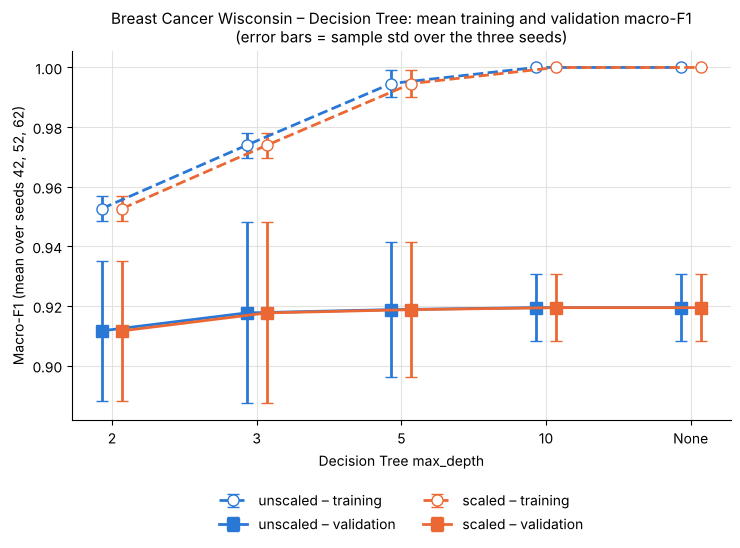

Saved figure: figures/breast_cancer_tree_depth_comparison.png


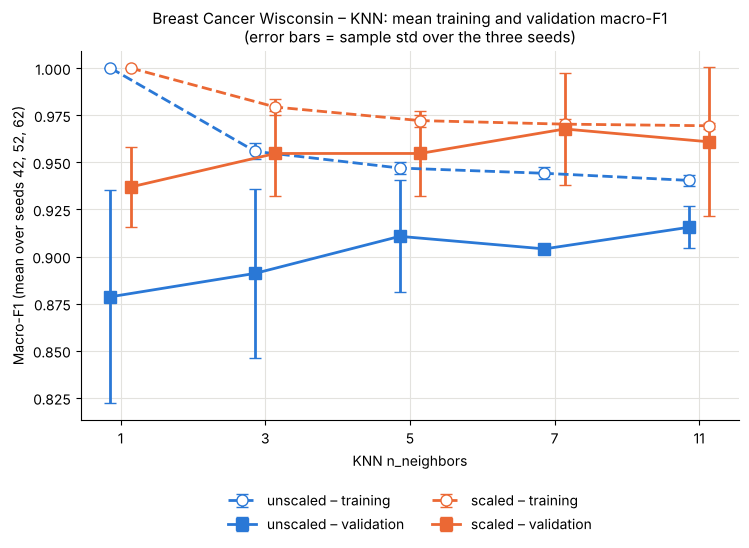

Saved figure: figures/breast_cancer_knn_neighbors_comparison.png


In [31]:
def plot_parameter_comparison(algorithm, xlabel, fig_name):
    """Mean training and validation macro-F1 against one parameter, both representations,
    with the standard deviation over the three seeds as error bars."""
    values = CLASSIFIER_GRID[algorithm][1]
    x = np.arange(len(values))
    fig, ax = plt.subplots(figsize=(8.5, 4.8))
    for representation, color, shift in zip(REPRESENTATIONS, CLASS_COLORS[:2], [-0.07, 0.07]):
        sub = (summary[(summary["algorithm"] == ALGORITHM_NAMES[algorithm])
                       & (summary["representation"] == representation)]
               .set_index("parameter").loc[[param_text(algorithm, v) for v in values]])
        ax.errorbar(x + shift, sub["train_macro_f1_mean"], yerr=sub["train_macro_f1_std"],
                    color=color, linestyle="--", linewidth=2, marker="o", markersize=8,
                    markerfacecolor="white", capsize=4, label=f"{representation} – training")
        ax.errorbar(x + shift, sub["val_macro_f1_mean"], yerr=sub["val_macro_f1_std"],
                    color=color, linestyle="-", linewidth=2, marker="s", markersize=8,
                    capsize=4, label=f"{representation} – validation")
    ax.set_xticks(x, [str(v) for v in values])
    ax.set_xlabel(xlabel)
    ax.set_ylabel("Macro-F1 (mean over seeds 42, 52, 62)")
    ax.set_title(f"{DATASET_TITLE} – {ALGORITHM_NAMES[algorithm]}: mean training and validation macro-F1\n"
                 "(error bars = sample std over the three seeds)")
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.16), ncol=2, frameon=False)
    save_fig(fig, fig_name)

plot_parameter_comparison("tree", "Decision Tree max_depth", "tree_depth_comparison")
plot_parameter_comparison("knn", "KNN n_neighbors", "knn_neighbors_comparison")

### Discussion of the validation results

**Selected configuration: `breast_cancer_knn_scaled_k7`** (KNN, scaled features, 7 neighbours) with mean validation macro-F1 = 0.9677 (std 0.0297) and mean validation accuracy = 0.9708. No tie-break was needed; the runner-up is `breast_cancer_knn_scaled_k11` (0.9608).

**Effect of scaling.**
* *Decision Tree:* scaled and unscaled results are exactly identical for every depth and every seed (difference 0.0000). A tree only compares one feature with a threshold, and standardisation does not change the order of the values.
* *KNN:* scaling helps at every neighbour count, by +0.044 to +0.064 mean validation macro-F1 (for example k = 7: 0.9040 → 0.9677; k = 3: 0.8910 → 0.9547). Without scaling the Euclidean distance is dominated by the area features.
* *Gaussian NB:* slightly lower with scaling (0.9369 → 0.9248, −0.012). This corresponds to 2 validation predictions out of 171 over the three seeds and is smaller than the seed standard deviation (about 0.02), so it should not be read as a real effect of scaling.

**Tree depth.** Mean training macro-F1 rises from 0.9527 (depth 2) to 1.0000 (depth 10 and None), but mean validation macro-F1 stays almost flat (0.9117 → 0.9177 → 0.9188 → 0.9195 → 0.9195). The training/validation gap therefore grows from 0.041 to 0.081: deeper trees memorise the training data without a matching validation gain. Depth 10 and None give identical results because the unrestricted trees stop at depth 6–8.

**Neighbour count (scaled).** With k = 1 the training score is 1.0000 by construction (each training point is its own nearest neighbour), but validation is 0.9369, a gap of 0.063. Larger k reduces the gap; for k = 7 training (0.9702) and validation (0.9677) are almost equal. Validation macro-F1 rises from k = 1 to k = 7 and then drops slightly at k = 11 (0.9608), so more neighbours did not always help.

**Variability across seeds.** The standard deviation of validation macro-F1 is between 0.001 and 0.057 across configurations. For the selected configuration the three values are 0.9615, 0.9415 and 1.0000 (std 0.0297). Each validation subset has only 57 samples, so one sample changes accuracy by about 1.75 percentage points. The difference between k = 7 and k = 11 (0.007) is much smaller than this spread, so the ranking among the scaled KNN settings is not firmly established. The standard deviation only describes these three overlapping splits; it is not a confidence interval and not evidence of statistical significance.

**Note on ROC-AUC.** KNN with k = 1 and fully grown trees output only probabilities of 0 or 1, so their ROC-AUC is coarse (KNN scaled: 0.9339 for k = 1 versus 0.9945 for k = 11).

## 9. Evaluating the Selected Models on the Test Sets

The selection is now frozen. Only the **seed-42 fitted instance** of the selected configuration is evaluated on the fixed test set, with the **seed-42 preprocessing**. The model is not refitted on training + validation, no other candidate is tested, and no seed is chosen by its score. This is a single final evaluation, not a new training run.

### 9.1 Final performance metrics

In [32]:
final_run_id = f"{SELECTED_CONFIG}_s{FINAL_SEED}"
final_model = fitted_models[final_run_id]                    # already fitted in Section 7
final_representation = selected_row["representation"]
X_test_final = test_representations[final_representation]    # seed-42 preprocessing

print("Selected configuration:", SELECTED_CONFIG)
print("Evaluated run (already fitted):", final_run_id)
print("Model:", final_model)
print("Test representation:", final_representation)

test_metrics = classifier_metrics(final_model, X_test_final, y_test)
y_test_pred = final_model.predict(X_test_final)
y_test_proba = final_model.predict_proba(X_test_final)
print("Undefined class precision/recall on the test set:", test_metrics["undefined"])

classifier_test = pd.DataFrame([{
    "dataset": DATASET_KEY,
    "selected_config": SELECTED_CONFIG,
    "evaluation_seed": FINAL_SEED,
    "val_macro_f1_mean": selected_row["val_macro_f1_mean"],
    "val_macro_f1_std": selected_row["val_macro_f1_std"],
    "test_accuracy": test_metrics["accuracy"],
    "test_macro_precision": test_metrics["macro_precision"],
    "test_macro_recall": test_metrics["macro_recall"],
    "test_macro_f1": test_metrics["macro_f1"],
    "test_roc_auc": test_metrics["roc_auc"],
}])
print(f"\n[{DATASET_TITLE}] Final test metrics (this dataset's row of the two-row final table)")
display(classifier_test)

Selected configuration: breast_cancer_knn_scaled_k7
Evaluated run (already fitted): breast_cancer_knn_scaled_k7_s42
Model: KNeighborsClassifier(metric='euclidean', n_neighbors=7)
Test representation: scaled
Undefined class precision/recall on the test set: all defined

[Breast Cancer Wisconsin] Final test metrics (this dataset's row of the two-row final table)


,dataset,selected_config,evaluation_seed,val_macro_f1_mean,val_macro_f1_std,test_accuracy,test_macro_precision,test_macro_recall,test_macro_f1,test_roc_auc
0,breast_cancer,breast_cancer_knn_scaled_k7,42,0.9677,0.0297,0.9737,0.98,0.9643,0.9713,0.9888


In [33]:
print(f"[{DATASET_TITLE}] Classification report – TEST set – {final_run_id}\n")
print(classification_report(y_test, y_test_pred, labels=list(final_model.classes_),
                            target_names=TARGET_NAMES, digits=4, zero_division=0))
report_dict = classification_report(y_test, y_test_pred, labels=list(final_model.classes_),
                                    target_names=TARGET_NAMES, output_dict=True, zero_division=0)

[Breast Cancer Wisconsin] Classification report – TEST set – breast_cancer_knn_scaled_k7_s42

              precision    recall  f1-score   support

   malignant     1.0000    0.9286    0.9630        42
      benign     0.9600    1.0000    0.9796        72

    accuracy                         0.9737       114
   macro avg     0.9800    0.9643    0.9713       114
weighted avg     0.9747    0.9737    0.9735       114



In [34]:
# Validation (seed 42 and mean over seeds) next to the test result of the same configuration
val42 = runs_df[runs_df["run_id"] == final_run_id].iloc[0]
compare_rows = []
for metric in ["accuracy", "macro_precision", "macro_recall", "macro_f1", "roc_auc"]:
    compare_rows.append({
        "metric": metric,
        "validation mean (3 seeds)": selected_row[f"val_{metric}_mean"],
        "validation std (3 seeds)": selected_row[f"val_{metric}_std"],
        "validation (seed 42)": val42[f"val_{metric}"],
        "test (seed 42 model)": test_metrics[metric],
    })
val_vs_test = pd.DataFrame(compare_rows)
val_vs_test["test − validation mean"] = val_vs_test["test (seed 42 model)"] - val_vs_test["validation mean (3 seeds)"]
print(f"[{DATASET_TITLE}] Validation vs test for {SELECTED_CONFIG}")
display(val_vs_test)
print(f"Validation subset size: {len(splits[FINAL_SEED]['y_val'])} samples; test set size: {len(y_test)} samples")

[Breast Cancer Wisconsin] Validation vs test for breast_cancer_knn_scaled_k7


,metric,validation mean (3 seeds),validation std (3 seeds),validation (seed 42),test (seed 42 model),test − validation mean
0,accuracy,0.9708,0.0268,0.9649,0.9737,0.0029
1,macro_precision,0.9784,0.0197,0.9737,0.9800,0.0016
2,macro_recall,0.9603,0.0364,0.9524,0.9643,0.0040
3,macro_f1,0.9677,0.0297,0.9615,0.9713,0.0036
4,roc_auc,0.9782,0.0194,0.9630,0.9888,0.0106


Validation subset size: 57 samples; test set size: 114 samples


**Validation versus test.** On the fixed test set the seed-42 model reaches accuracy 0.9737, macro-precision 0.9800, macro-recall 0.9643, macro-F1 0.9713 and ROC-AUC 0.9888. The mean validation macro-F1 of this configuration was 0.9677 (std 0.0297), and its seed-42 validation macro-F1 was 0.9615. The test macro-F1 is 0.0036 above the validation mean, far inside one standard deviation, so the validation estimate and the test result agree and there is no sign that the selection was over-fitted to the validation subsets. The test ROC-AUC (0.9888) is about 0.011 higher than the validation mean (0.9782), also within the validation spread. The selected model is **not** changed after seeing these results.

### 9.2 Confusion matrices

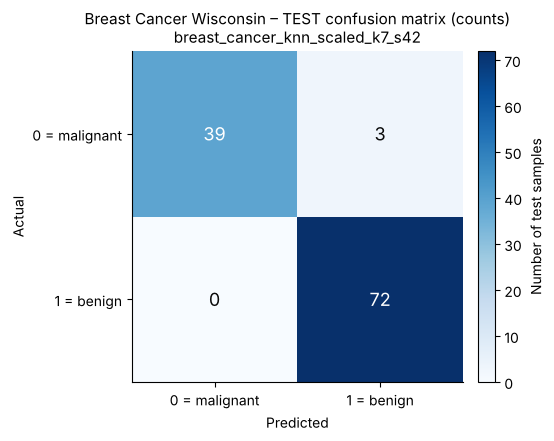

Saved figure: figures/breast_cancer_test_confusion_matrix.png
[Breast Cancer Wisconsin] TEST confusion matrix as a table (counts) – breast_cancer_knn_scaled_k7_s42


,Predicted malignant,Predicted benign
Actual malignant,39,3
Actual benign,0,72


In [35]:
cm_labels = list(final_model.classes_)                # class order [0, 1] = [malignant, benign]
cm = confusion_matrix(y_test, y_test_pred, labels=cm_labels)

fig, ax = plt.subplots(figsize=(1.9 + 1.5 * len(cm_labels), 1.5 + 1.4 * len(cm_labels)))
im = ax.imshow(cm, cmap="Blues", vmin=0)
tick_names = [f"{c} = {n}" for c, n in zip(cm_labels, TARGET_NAMES)]
ax.set_xticks(range(len(cm_labels)), tick_names)
ax.set_yticks(range(len(cm_labels)), tick_names)
ax.set_xlabel("Predicted")
ax.set_ylabel("Actual")
ax.grid(False)
for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        ax.text(j, i, str(cm[i, j]), ha="center", va="center", fontsize=13,
                color="white" if cm[i, j] > cm.max() / 2 else "#0b0b0b")
fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04).set_label("Number of test samples")
ax.set_title(f"{DATASET_TITLE} – TEST confusion matrix (counts)\n{final_run_id}")
save_fig(fig, "test_confusion_matrix")

cm_table = pd.DataFrame(cm, index=[f"Actual {n}" for n in TARGET_NAMES],
                        columns=[f"Predicted {n}" for n in TARGET_NAMES])
print(f"[{DATASET_TITLE}] TEST confusion matrix as a table (counts) – {final_run_id}")
display(cm_table)

In [36]:
# Reading the matrix with class order [0, 1] = [malignant, benign] and MALIGNANT as the positive class.
# This is NOT the usual [[TN, FP], [FN, TP]] layout, because the positive class is in the first row/column:
#
#                      Predicted malignant   Predicted benign
#   Actual malignant          TP                    FN
#   Actual benign             FP                    TN
TP, FN = int(cm[0, 0]), int(cm[0, 1])
FP, TN = int(cm[1, 0]), int(cm[1, 1])
print(f"True positives  (TP) = {TP}: malignant tumours correctly predicted as malignant")
print(f"False negatives (FN) = {FN}: malignant tumours predicted as benign (missed cancers)")
print(f"False positives (FP) = {FP}: benign tumours predicted as malignant (false alarms)")
print(f"True negatives  (TN) = {TN}: benign tumours correctly predicted as benign")
print(f"Check: TP + FN + FP + TN = {TP + FN + FP + TN} = number of test samples ({len(y_test)})")

True positives  (TP) = 39: malignant tumours correctly predicted as malignant
False negatives (FN) = 3: malignant tumours predicted as benign (missed cancers)
False positives (FP) = 0: benign tumours predicted as malignant (false alarms)
True negatives  (TN) = 72: benign tumours correctly predicted as benign
Check: TP + FN + FP + TN = 114 = number of test samples (114)


In [37]:
def manual_class_metrics(cm, pos):
    """Precision, recall and F1 for one class (row/column position `pos`) versus all other classes,
    calculated by hand from the confusion-matrix counts."""
    tp = int(cm[pos, pos])
    fn = int(cm[pos, :].sum() - tp)
    fp = int(cm[:, pos].sum() - tp)
    tn = int(cm.sum() - tp - fn - fp)
    precision = tp / (tp + fp) if (tp + fp) > 0 else None     # None = undefined (zero denominator)
    recall = tp / (tp + fn) if (tp + fn) > 0 else None
    if precision is None or recall is None or (precision + recall) == 0:
        f1 = None
    else:
        f1 = 2 * precision * recall / (precision + recall)
    return tp, fp, fn, tn, precision, recall, f1

MANUAL_CLASS = 0                                   # malignant = positive class
pos = cm_labels.index(MANUAL_CLASS)
class_name = TARGET_NAMES[pos]
tp, fp, fn, tn, p_manual, r_manual, f_manual = manual_class_metrics(cm, pos)

fmt = lambda v: "undefined (zero denominator)" if v is None else f"{v:.4f}"
print(f"[{DATASET_TITLE}] Manual check for class {MANUAL_CLASS} ({class_name}) versus all other classes")
print(f"  TP = {tp}, FP = {fp}, FN = {fn}, TN = {tn}")
print(f"  precision = TP / (TP + FP) = {tp} / ({tp} + {fp}) = {fmt(p_manual)}")
print(f"  recall    = TP / (TP + FN) = {tp} / ({tp} + {fn}) = {fmt(r_manual)}")
print(f"  F1        = 2 · precision · recall / (precision + recall) = {fmt(f_manual)}")

manual_check = pd.DataFrame({
    "metric": ["precision", "recall", "f1-score"],
    "manual (from confusion matrix)": [p_manual, r_manual, f_manual],
    f"classification report (class {class_name})": [report_dict[class_name]["precision"],
                                                    report_dict[class_name]["recall"],
                                                    report_dict[class_name]["f1-score"]],
})
manual_check["match"] = [
    (m is not None) and bool(np.isclose(m, r))
    for m, r in zip(manual_check.iloc[:, 1], manual_check.iloc[:, 2])]
display(manual_check)
print("Support of this class in the report:", int(report_dict[class_name]["support"]), "= TP + FN =", tp + fn)

[Breast Cancer Wisconsin] Manual check for class 0 (malignant) versus all other classes
  TP = 39, FP = 0, FN = 3, TN = 72
  precision = TP / (TP + FP) = 39 / (39 + 0) = 1.0000
  recall    = TP / (TP + FN) = 39 / (39 + 3) = 0.9286
  F1        = 2 · precision · recall / (precision + recall) = 0.9630


,metric,manual (from confusion matrix),classification report (class malignant),match
0,precision,1.0000,1.0000,True
1,recall,0.9286,0.9286,True
2,f1-score,0.9630,0.9630,True


Support of this class in the report: 42 = TP + FN = 42


**Reading the confusion matrix.** The class order is `[0, 1] = [malignant, benign]` and malignant is the positive class, so the top-left cell is TP and the bottom-right cell is TN (this is the opposite of the usual TN-first layout):

* **TP = 39** malignant tumours predicted as malignant;
* **FN = 3** malignant tumours predicted as benign (first row, second column);
* **FP = 0** benign tumours predicted as malignant (second row, first column);
* **TN = 72** benign tumours predicted as benign.

All three test errors are false negatives; no benign case was flagged as malignant.

**Manual check (malignant class).** precision = 39 / (39 + 0) = 1.0000, recall = 39 / (39 + 3) = 0.9286 and F1 = 2 · 1.0000 · 0.9286 / (1.0000 + 0.9286) = 0.9630. These values match the **malignant row** of the classification report (they are compared with the per-class values, not with the macro averages 0.9800 / 0.9643 / 0.9713). No denominator is zero, so no metric is undefined.

### 9.3 ROC curves

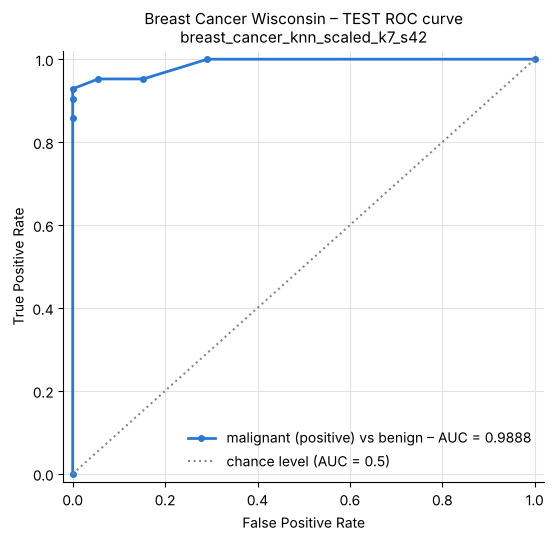

Saved figure: figures/breast_cancer_test_roc_curve.png
Test ROC-AUC (malignant positive): 0.9888
Distinct thresholds on the curve: 8
[Breast Cancer Wisconsin] Points of the TEST ROC curve of breast_cancer_knn_scaled_k7_s42 (descriptive only – no new threshold is chosen):


,threshold on P(malignant),FPR,TPR
0,inf,0.0000,0.0000
1,1.0000,0.0000,0.8571
2,0.8571,0.0000,0.9048
3,0.7143,0.0000,0.9286
4,0.4286,0.0556,0.9524
5,0.2857,0.1528,0.9524
6,0.1429,0.2917,1.0000
7,0.0000,1.0000,1.0000


In [38]:
# Malignant-versus-benign ROC curve (same evaluation target and probability column as in Section 8)
pos_col = list(final_model.classes_).index(POSITIVE_CLASS)
y_eval_test = (y_test.values == POSITIVE_CLASS).astype(int)       # 1 = malignant, 0 = benign
malignant_score = y_test_proba[:, pos_col]                        # P(original class 0)
fpr, tpr, thresholds = roc_curve(y_eval_test, malignant_score)
roc_auc_value = auc(fpr, tpr)
assert np.isclose(roc_auc_value, test_metrics["roc_auc"])

fig, ax = plt.subplots(figsize=(6.2, 5.6))
ax.plot(fpr, tpr, color=CLASS_COLORS[0], linewidth=2, marker="o", markersize=4,
        label=f"malignant (positive) vs benign – AUC = {roc_auc_value:.4f}")
ax.plot([0, 1], [0, 1], color="#8a8985", linestyle=":", linewidth=1.5, label="chance level (AUC = 0.5)")
ax.set_xlabel("False Positive Rate")
ax.set_ylabel("True Positive Rate")
ax.set_title(f"{DATASET_TITLE} – TEST ROC curve\n{final_run_id}")
ax.legend(loc="lower right", frameon=False)
ax.set_xlim(-0.02, 1.02); ax.set_ylim(-0.02, 1.02)
save_fig(fig, "test_roc_curve")

print(f"Test ROC-AUC (malignant positive): {roc_auc_value:.4f}")
print(f"Distinct thresholds on the curve: {len(thresholds)}")
roc_points = pd.DataFrame({"threshold on P(malignant)": thresholds, "FPR": fpr, "TPR": tpr})
print(f"[{DATASET_TITLE}] Points of the TEST ROC curve of {final_run_id} (descriptive only – no new threshold is chosen):")
display(roc_points)

**Interpretation.** The test ROC-AUC with malignant as the positive class is 0.9888. The curve has only a few points because a 7-neighbour KNN can output only eight different probabilities (0/7, 1/7, …, 7/7).

**Effect of the decision threshold (in my own words).** A sample is called malignant when its predicted probability of being malignant is at least the threshold. If the threshold is lowered, more samples are called malignant: fewer malignant tumours are missed (fewer false negatives, higher TPR), but more benign tumours are wrongly flagged (more false positives, higher FPR). If the threshold is raised, the opposite happens. The curve shows this trade-off: with a high threshold the model catches 92.9% of the malignant cases with no false positives; to catch 95.2% it must accept a false positive rate of 5.6%; and it only reaches 100% when 29.2% of the benign cases are also flagged.

This figure is descriptive only. No new threshold is chosen and nothing is tuned on the test set; the reported predictions use the classifier's standard majority vote.

### 9.4 Error interpretation

In [39]:
errors = pd.DataFrame({
    "actual_label": y_test.values,
    "actual_name": [TARGET_NAMES[cm_labels.index(c)] for c in y_test.values],
    "predicted_label": y_test_pred,
    "predicted_name": [TARGET_NAMES[cm_labels.index(c)] for c in y_test_pred],
}, index=X_test.index)
for j, c in enumerate(cm_labels):
    errors[f"proba_class_{c}"] = y_test_proba[:, j]
errors.index.name = "original_row_index"
errors = errors[errors["actual_label"] != errors["predicted_label"]]

print(f"[{DATASET_TITLE}] Test misclassifications of {final_run_id}: {len(errors)} of {len(y_test)}")
if len(errors) == 0:
    print("=> The selected classifier makes NO errors on the test set.")
else:
    display(errors)

[Breast Cancer Wisconsin] Test misclassifications of breast_cancer_knn_scaled_k7_s42: 3 of 114


,actual_label,actual_name,predicted_label,predicted_name,proba_class_0,proba_class_1
original_row_index,,,,,,
41,0,malignant,1,benign,0.4286,0.5714
73,0,malignant,1,benign,0.1429,0.8571
205,0,malignant,1,benign,0.1429,0.8571


In [40]:
# Closer look at one actual misclassification: the one with the most confident wrong prediction.
# Feature ranking and class means come from the seed-42 TRAINING data only.
X_tr42, y_tr42 = splits[FINAL_SEED]["X_train"], splits[FINAL_SEED]["y_train"]
f_values, _ = f_classif(X_tr42, y_tr42)
f_scores = pd.Series(f_values, index=X.columns).sort_values(ascending=False)

if len(errors) > 0:
    wrong_proba = errors.apply(lambda r: r[f"proba_class_{int(r['predicted_label'])}"], axis=1)
    error_idx = wrong_proba.idxmax()
    e = errors.loc[error_idx]
    print(f"Examined test sample: original row index {error_idx}")
    print(f"  actual class:    {int(e['actual_label'])} ({e['actual_name']})")
    print(f"  predicted class: {int(e['predicted_label'])} ({e['predicted_name']})")
    print("  predicted probabilities:",
          {f"class {c}": round(float(e[f'proba_class_{c}']), 4) for c in cm_labels})
    top_feats = list(f_scores.index[:6])
    detail = pd.DataFrame({
        "value of this sample": X_test.loc[error_idx, top_feats],
        f"training mean of actual class ({e['actual_name']})":
            X_tr42.loc[y_tr42 == e["actual_label"], top_feats].mean(),
        f"training mean of predicted class ({e['predicted_name']})":
            X_tr42.loc[y_tr42 == e["predicted_label"], top_feats].mean(),
    })
    print(f"\n[{DATASET_TITLE}] Test row {error_idx}: its values on the six features with the highest "
          "training ANOVA F-score, next to the seed-42 training class means")
    display(detail)
else:
    print("No misclassified test sample to examine.")

Examined test sample: original row index 73
  actual class:    0 (malignant)
  predicted class: 1 (benign)
  predicted probabilities: {'class 0': 0.1429, 'class 1': 0.8571}

[Breast Cancer Wisconsin] Test row 73: its values on the six features with the highest training ANOVA F-score, next to the seed-42 training class means


,value of this sample,training mean of actual class (malignant),training mean of predicted class (benign)
worst concave points,0.1383,0.1858,0.0733
mean concave points,0.0507,0.0899,0.0253
worst perimeter,110.3000,141.6175,86.5400
worst radius,16.5700,21.1438,13.3191
mean perimeter,90.4300,115.5578,77.7604
worst area,812.4000,1421.5322,554.5442


**One actual misclassification.** The selected model makes 3 test errors (original rows 41, 73 and 205), all malignant tumours predicted as benign. The examined case is **row 73**: it is truly malignant, but 6 of its 7 nearest training neighbours are benign, so the predicted probability of malignant is only 1/7 = 0.1429. Its values lie between the two class means of the training data: `worst concave points` is 0.138 (malignant mean 0.186, benign mean 0.073), `worst radius` is 16.57 (21.14 vs 13.32) and `worst area` is 812 (1422 vs 555). In other words, it is a rather small malignant tumour located in the region where the two classes overlap, and in the scaled 30-feature space it is surrounded by benign cases.

**What the error means.** It is a false negative: a cancer that would be reported as benign. In this application that is the more serious type of error, because a missed malignant tumour may delay treatment, whereas a false positive leads to further tests.

**Limitations.** The validation subsets are small (57 samples), and the three repetitions overlap heavily because they are drawn from the same 455 rows, so the standard deviations probably understate the real uncertainty. Only the predeclared seed-42 instance was tested, once, on one test set of 114 samples (42 malignant). The three validation repetitions are not repeated independent test results, and no experiment beyond those shown here was run.

## 10. K-Means Clustering

K-Means is **unsupervised**: `y` is never passed to `KMeans.fit`, and the cluster IDs it returns are arbitrary numbers, **not class labels**.

### 10.1 Fit the clustering model

* `n_clusters = 2` (fixed to the number of classes for comparison, not chosen by an unsupervised search);
* `random_state = seed`, `n_init = 10` (ten internal initialisations inside one fit; this is still one reported run);
* all original features, the same training indices as the classifiers, both representations, all three seeds → 6 fits.

In [41]:
def safe_silhouette(X_part, clusters):
    """Silhouette score, or NaN when it is undefined
    (needs at least 2 distinct predicted clusters and fewer clusters than samples)."""
    n_found = len(np.unique(clusters))
    if n_found < 2 or n_found >= len(clusters):
        return np.nan
    return silhouette_score(X_part, clusters)

kmeans_models = {}
kmeans_rows = []
for seed in SEEDS:
    for representation in REPRESENTATIONS:
        X_tr = representations[seed][representation]["X_train"]
        X_va = representations[seed][representation]["X_val"]
        y_va = splits[seed]["y_val"]

        km = KMeans(n_clusters=N_CLUSTERS, random_state=seed, n_init=10)
        km.fit(X_tr)                                   # features only – no labels
        kmeans_models[(representation, seed)] = km

        val_clusters = km.predict(X_va)
        kmeans_rows.append({
            "dataset": DATASET_KEY,
            "run_id": f"{DATASET_KEY}_kmeans_{representation}_k{N_CLUSTERS}_s{seed}",
            "seed": seed, "representation": representation,
            "n_clusters": N_CLUSTERS, "n_init": 10,
            "train_inertia": km.inertia_,
            "val_ari": adjusted_rand_score(y_va, val_clusters),      # labels used for evaluation only
            "val_silhouette": safe_silhouette(X_va, val_clusters),   # same feature space as the model
            "val_distinct_clusters": len(np.unique(val_clusters)),
        })

kmeans_runs = pd.DataFrame(kmeans_rows)
assert len(kmeans_runs) == 6
print(f"[{DATASET_TITLE}] K-Means run table: {len(kmeans_runs)} fits")
display(kmeans_runs)

[Breast Cancer Wisconsin] K-Means run table: 6 fits


,dataset,run_id,seed,representation,n_clusters,n_init,train_inertia,val_ari,val_silhouette,val_distinct_clusters
0,breast_cancer,breast_cancer_kmeans_unscaled_k2_s42,42,unscaled,2,10,5.1565e+07,0.3995,0.6387,2
1,breast_cancer,breast_cancer_kmeans_scaled_k2_s42,42,scaled,2,10,7.9188e+03,0.4516,0.2854,2
2,breast_cancer,breast_cancer_kmeans_unscaled_k2_s52,52,unscaled,2,10,4.9191e+07,0.6122,0.6975,2
3,breast_cancer,breast_cancer_kmeans_scaled_k2_s52,52,scaled,2,10,8.0030e+03,0.5586,0.3750,2
4,breast_cancer,breast_cancer_kmeans_unscaled_k2_s62,62,unscaled,2,10,5.3056e+07,0.5013,0.6958,2
5,breast_cancer,breast_cancer_kmeans_scaled_k2_s62,62,scaled,2,10,7.9225e+03,0.7336,0.2758,2


In [42]:
kmeans_summary = (kmeans_runs.groupby(["dataset", "representation"], sort=False)
                  .agg(n_runs=("seed", "count"),
                       train_inertia_mean=("train_inertia", "mean"),
                       train_inertia_std=("train_inertia", "std"),
                       val_ari_mean=("val_ari", "mean"),
                       val_ari_std=("val_ari", "std"),
                       val_ari_valid_count=("val_ari", "count"),
                       val_silhouette_mean=("val_silhouette", "mean"),      # NaN (N/A) values are skipped,
                       val_silhouette_std=("val_silhouette", "std"),        # never replaced by zero
                       val_silhouette_valid_count=("val_silhouette", "count"))
                  .reset_index())
assert len(kmeans_summary) == 2
print(f"[{DATASET_TITLE}] K-Means summary: mean and sample std (ddof=1) over the three seeds, one row per representation")
display(kmeans_summary)
print("Note: inertia is a sum of squared distances in the feature space of each representation.")
print("The unscaled and scaled inertia values have different units and must not be compared with each other.")

[Breast Cancer Wisconsin] K-Means summary: mean and sample std (ddof=1) over the three seeds, one row per representation


,dataset,representation,n_runs,train_inertia_mean,train_inertia_std,val_ari_mean,val_ari_std,val_ari_valid_count,val_silhouette_mean,val_silhouette_std,val_silhouette_valid_count
0,breast_cancer,unscaled,3,5.1271e+07,1.9496e+06,0.5043,0.1064,3,0.6773,0.0334,3
1,breast_cancer,scaled,3,7.9481e+03,4.7574e+01,0.5813,0.1424,3,0.3121,0.0547,3


Note: inertia is a sum of squared distances in the feature space of each representation.
The unscaled and scaled inertia values have different units and must not be compared with each other.


**Validation results.** All six fits produce two non-empty clusters on their validation subset, so ARI and silhouette are defined in every run (valid count 3 of 3).

* **ARI (agreement with the true classes):** unscaled mean 0.504 (std 0.106), scaled mean 0.581 (std 0.142). The scaled mean is higher, but the order is not the same in every seed (for seed 52 the unscaled model is higher: 0.612 vs 0.559) and the difference of the means (0.077) is smaller than the standard deviations. On validation there is no clear winner.
* **Silhouette:** unscaled 0.677, scaled 0.312. These numbers are calculated in two different feature spaces. In the unscaled space the distances are dominated by the area features, so the clusters look compact there; this does not show that the unscaled partition is better.
* **Inertia:** about 5.1 × 10⁷ (unscaled) and 7.9 × 10³ (scaled). The units are different, so these two values are not compared.

### 10.2 Final cluster evaluation on the fixed test sets

For **seed 42 only**, the already fitted K-Means models predict the test clusters for both representations (no new fits). Both representations are reported; neither is selected by its test score. The true labels are used only to evaluate the partition (ARI and contingency tables), never to fit or to rename clusters.

In [43]:
kmeans_test_rows = []
test_clusters = {}
contingency_tables = {}
for representation in REPRESENTATIONS:
    km = kmeans_models[(representation, FINAL_SEED)]            # fitted in 10.1
    X_te = test_representations[representation]                 # seed-42 preprocessing
    clusters = km.predict(X_te)
    test_clusters[representation] = clusters
    cluster_counts = {int(k): int((clusters == k).sum()) for k in range(N_CLUSTERS)}

    kmeans_test_rows.append({
        "dataset": DATASET_KEY, "representation": representation, "seed": FINAL_SEED,
        "n_clusters": N_CLUSTERS, "n_test_samples": len(X_te),
        "test_cluster_counts": "; ".join(f"cluster {k}: {n}" for k, n in cluster_counts.items()),
        "test_distinct_clusters": len(np.unique(clusters)),
        "test_ari": adjusted_rand_score(y_test, clusters),
        "test_silhouette": safe_silhouette(X_te, clusters),
    })

    contingency_tables[representation] = pd.crosstab(
        pd.Series([f"{c} = {TARGET_NAMES[CLASS_LABELS.index(c)]}" for c in y_test.values], name="true class"),
        pd.Series([f"cluster {k}" for k in clusters], name="predicted cluster"))

kmeans_test = pd.DataFrame(kmeans_test_rows)
print(f"[{DATASET_TITLE}] Final K-Means test evaluation (seed 42, both representations)")
with pd.option_context("display.max_colwidth", None):
    display(kmeans_test)

for representation in REPRESENTATIONS:
    print(f"\n[{DATASET_TITLE}] Class-versus-cluster contingency table – TEST set – {representation} features (seed 42)")
    display(contingency_tables[representation])

[Breast Cancer Wisconsin] Final K-Means test evaluation (seed 42, both representations)


,dataset,representation,seed,n_clusters,n_test_samples,test_cluster_counts,test_distinct_clusters,test_ari,test_silhouette
0,breast_cancer,unscaled,42,2,114,cluster 0: 86; cluster 1: 28,2,0.5585,0.7120
1,breast_cancer,scaled,42,2,114,cluster 0: 74; cluster 1: 40,2,0.7354,0.3251



[Breast Cancer Wisconsin] Class-versus-cluster contingency table – TEST set – unscaled features (seed 42)


predicted cluster,cluster 0,cluster 1
true class,,
0 = malignant,14,28
1 = benign,72,0



[Breast Cancer Wisconsin] Class-versus-cluster contingency table – TEST set – scaled features (seed 42)


predicted cluster,cluster 0,cluster 1
true class,,
0 = malignant,5,37
1 = benign,69,3


**Final test evaluation (seed 42, no new fits).**

| Representation | Test cluster counts | ARI | Silhouette |
|---|---|---|---|
| unscaled | cluster 0: 86, cluster 1: 28 | 0.5585 | 0.7120 |
| scaled | cluster 0: 74, cluster 1: 40 | 0.7354 | 0.3251 |

**Contingency tables.** With **unscaled** features, cluster 1 contains only malignant cases (28), but cluster 0 mixes all 72 benign cases with 14 malignant cases, i.e. one third of the malignant test cases are grouped together with the benign ones. With **scaled** features the mixing is smaller: cluster 0 holds 69 benign and 5 malignant cases, and cluster 1 holds 37 malignant and 3 benign cases.

K-Means never saw the labels, yet its two clusters partly follow the two classes. ARI measures the agreement of two partitions corrected for chance; it is **not** a classification accuracy, and the cluster numbers 0 and 1 are not class labels. Both representations are reported and neither is selected by its test score.

### 10.3 Visualise and interpret the clusters

Two original features are chosen with the **seed-42 training data only**: the feature with the highest ANOVA F-score (`f_classif`), and the next-highest feature whose absolute training correlation with the first one is below 0.7 (so that the two axes are not almost the same measurement). The same two features are used for both representations.

In [44]:
feature_a = f_scores.index[0]
train_corr_with_a = X_tr42.corr()[feature_a].abs()
feature_b = next(f for f in f_scores.index[1:] if train_corr_with_a[f] < 0.7)
print(f"[{DATASET_TITLE}] Features chosen for the plots (from seed-42 training data):")
print(f"  x-axis: {feature_a}  (F = {f_scores[feature_a]:.1f})")
print(f"  y-axis: {feature_b}  (F = {f_scores[feature_b]:.1f}, |r| with x-axis feature = {train_corr_with_a[feature_b]:.2f})")

[Breast Cancer Wisconsin] Features chosen for the plots (from seed-42 training data):
  x-axis: worst concave points  (F = 770.0)
  y-axis: radius error  (F = 194.6, |r| with x-axis feature = 0.54)


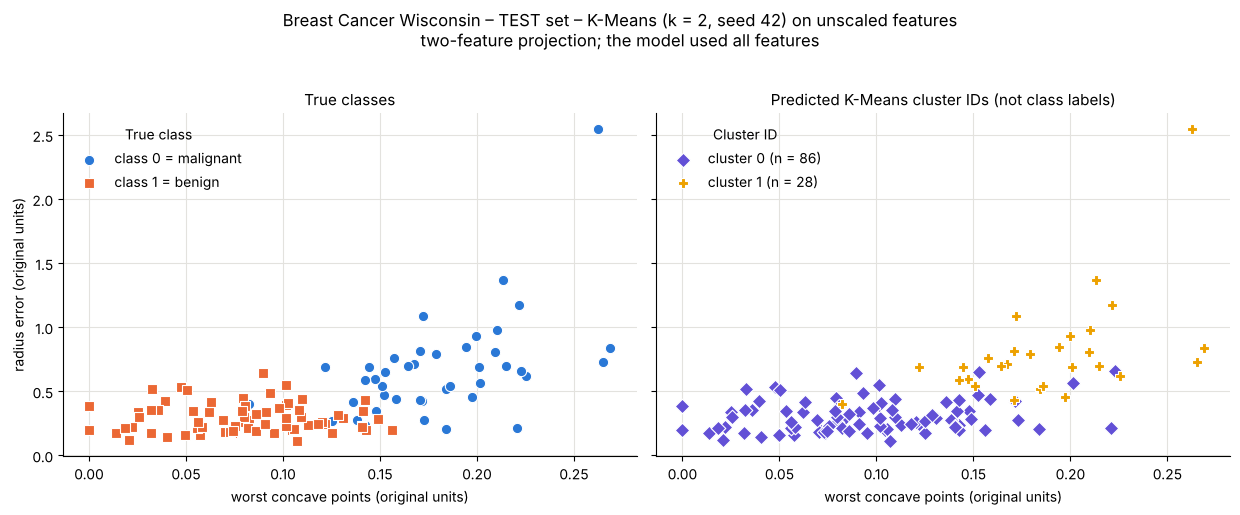

Saved figure: figures/breast_cancer_kmeans_test_unscaled.png


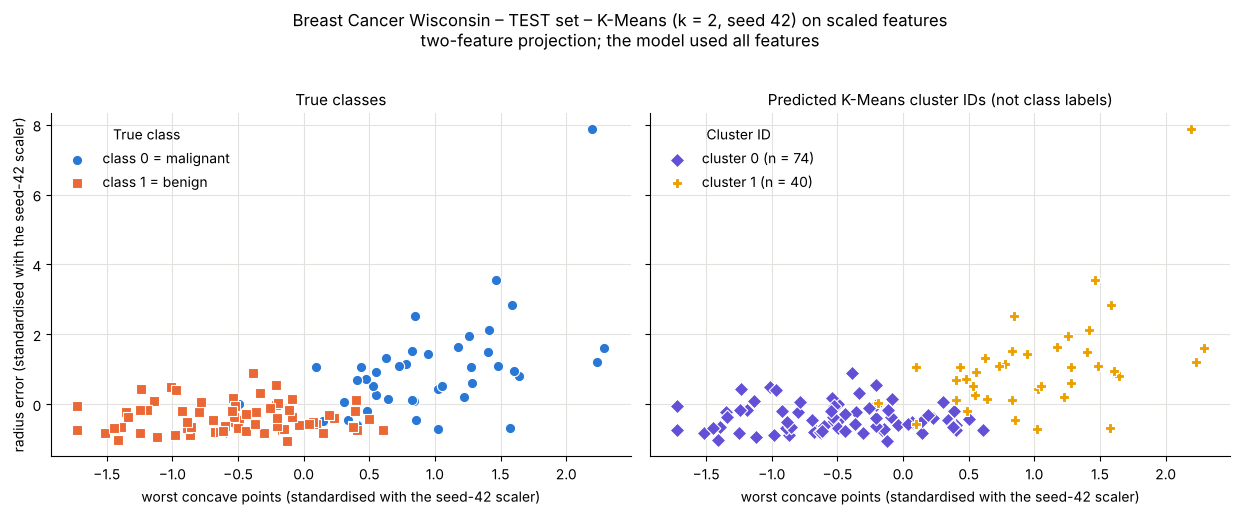

Saved figure: figures/breast_cancer_kmeans_test_scaled.png


In [45]:
def plot_classes_vs_clusters(representation):
    X_te = test_representations[representation]
    clusters = test_clusters[representation]
    fig, axes = plt.subplots(1, 2, figsize=(12.5, 5), sharex=True, sharey=True)

    for c, name, color, marker in zip(CLASS_LABELS, TARGET_NAMES, CLASS_COLORS, CLASS_MARKERS):
        mask = (y_test == c).values
        axes[0].scatter(X_te.loc[mask, feature_a], X_te.loc[mask, feature_b], s=55, color=color,
                        marker=marker, edgecolor="white", linewidth=0.8, label=f"class {c} = {name}")
    axes[0].set_title("True classes")
    axes[0].legend(frameon=False, title="True class")

    for k, color, marker in zip(range(N_CLUSTERS), CLUSTER_COLORS, CLUSTER_MARKERS):
        mask = clusters == k
        axes[1].scatter(X_te.loc[mask, feature_a], X_te.loc[mask, feature_b], s=55, color=color,
                        marker=marker, edgecolor="white", linewidth=0.8,
                        label=f"cluster {k} (n = {int(mask.sum())})")
    axes[1].set_title("Predicted K-Means cluster IDs (not class labels)")
    axes[1].legend(frameon=False, title="Cluster ID")

    unit = "original units" if representation == "unscaled" else "standardised with the seed-42 scaler"
    for ax in axes:
        ax.set_xlabel(f"{feature_a} ({unit})")
    axes[0].set_ylabel(f"{feature_b} ({unit})")
    fig.suptitle(f"{DATASET_TITLE} – TEST set – K-Means (k = {N_CLUSTERS}, seed 42) on {representation} features\n"
                 "two-feature projection; the model used all features", y=1.02)
    fig.tight_layout()
    save_fig(fig, f"kmeans_test_{representation}")

for representation in REPRESENTATIONS:
    plot_classes_vs_clusters(representation)

**Chosen features (from the seed-42 training data):** `worst concave points` (x-axis) and `radius error` (y-axis).

**Classes versus clusters.** In the true-class panels the malignant cases lie to the right (higher `worst concave points`) and tend to have a higher `radius error`; the classes overlap in the middle. With **unscaled** features, cluster 1 (28 samples) covers only part of the malignant region, and many malignant points are in cluster 0 together with the benign ones. The reason is that the unscaled clustering is driven almost only by the area features, so it separates "very large" tumours from all others. With **scaled** features all 30 features contribute, cluster 1 grows to 40 samples and the cluster panel looks much more like the class panel; only the points in the overlap region are mixed.

The model used all 30 features; these plots are only a two-feature projection, so points that look close here can be far apart in the full space.

**Effect of scaling.** Scaling changes the partition itself, not only its score. The silhouette is higher for the unscaled model (0.712 vs 0.325) although its agreement with the classes is lower (ARI 0.559 vs 0.735). Silhouette depends on the feature space, so this difference alone is not proof of a better or worse model.

**Information available during fitting.** K-Means received only the training feature matrix and the number of clusters. It never received `y_train`; it only minimises the squared distances of the points to their cluster centres, and its cluster IDs are arbitrary. The three classifiers received both the features and the labels, so they could learn which features and which values separate malignant from benign. For K-Means the labels were used only after fitting, to calculate ARI and the contingency tables.

## Export: results for the shared CSV files and run inventory

The six CSV files combine both datasets and contain a `dataset` column. Each notebook replaces **only its own dataset's rows** in every file, so the two notebooks can be run in any order and re-running one never duplicates rows.

In [46]:
DATASET_ORDER = ["breast_cancer", "wine"]

def save_combined(df, filename):
    """Write this dataset's rows into a shared CSV file (rows of the other dataset are kept)."""
    path = RESULTS_DIR / filename
    if path.exists():
        old = pd.read_csv(path, float_precision="round_trip")   # exact values, independent of run order
        old = old[old["dataset"] != DATASET_KEY]
        combined = pd.concat([old, df], ignore_index=True) if len(old) else df.copy()
    else:
        combined = df.copy()
    combined["_order"] = combined["dataset"].map({k: i for i, k in enumerate(DATASET_ORDER)})
    combined = combined.sort_values("_order", kind="stable").drop(columns="_order")
    combined.to_csv(path, index=False)
    return len(df), len(combined)

exports = {
    "classifier_runs.csv": runs_df,
    "classifier_summary.csv": summary,
    "classifier_test.csv": classifier_test,
    "kmeans_runs.csv": kmeans_runs,
    "kmeans_summary.csv": kmeans_summary,
    "kmeans_test.csv": kmeans_test,
}
required_per_dataset = {"classifier_runs.csv": 66, "classifier_summary.csv": 22, "classifier_test.csv": 1,
                        "kmeans_runs.csv": 6, "kmeans_summary.csv": 2, "kmeans_test.csv": 2}
export_rows = []
for filename, df in exports.items():
    n_here, n_total = save_combined(df, filename)
    assert n_here == required_per_dataset[filename]
    export_rows.append({"csv_file": f"results/{filename}", "rows from this dataset": n_here,
                        "required per dataset": required_per_dataset[filename],
                        "rows in file now (both datasets when complete)": n_total})
print(f"[{DATASET_TITLE}] Rows written to the six shared CSV files")
display(pd.DataFrame(export_rows))

[Breast Cancer Wisconsin] Rows written to the six shared CSV files


,csv_file,rows from this dataset,required per dataset,rows in file now (both datasets when complete)
0,results/classifier_runs.csv,66,66,132
1,results/classifier_summary.csv,22,22,44
2,results/classifier_test.csv,1,1,2
3,results/kmeans_runs.csv,6,6,12
4,results/kmeans_summary.csv,2,2,4
5,results/kmeans_test.csv,2,2,4


In [47]:
# Run inventory for this dataset
n_classifier_fits = len(runs_df)
n_kmeans_fits = len(kmeans_runs)
print(f"[{DATASET_TITLE}] classifier fits: {n_classifier_fits}  +  K-Means fits: {n_kmeans_fits}  "
      f"=  {n_classifier_fits + n_kmeans_fits} model fits for this dataset")
print("Test evaluations reuse seed-42 fitted models (1 classifier + 2 clusterings) and add no fits.")
assert n_classifier_fits == 66 and n_kmeans_fits == 6

figure_files = sorted(p.name for p in FIG_DIR.glob(f"{DATASET_KEY}_*.png"))
print(f"\nFigure files written by this notebook: {len(figure_files)}")
for name in figure_files:
    print("  figures/" + name)

[Breast Cancer Wisconsin] classifier fits: 66  +  K-Means fits: 6  =  72 model fits for this dataset
Test evaluations reuse seed-42 fitted models (1 classifier + 2 clusterings) and add no fits.

Figure files written by this notebook: 11
  figures/breast_cancer_boxplots_error.png
  figures/breast_cancer_boxplots_mean.png
  figures/breast_cancer_boxplots_worst.png
  figures/breast_cancer_class_distribution.png
  figures/breast_cancer_correlation_heatmap.png
  figures/breast_cancer_kmeans_test_scaled.png
  figures/breast_cancer_kmeans_test_unscaled.png
  figures/breast_cancer_knn_neighbors_comparison.png
  figures/breast_cancer_test_confusion_matrix.png
  figures/breast_cancer_test_roc_curve.png
  figures/breast_cancer_tree_depth_comparison.png


### Combined final tables (both datasets)

The two-row final classifier test table and the four-row final K-Means test table, read back from the shared CSV files. They are complete once both notebooks have been run.

In [48]:
combined_clf_test = pd.read_csv(RESULTS_DIR / "classifier_test.csv")
combined_km_test = pd.read_csv(RESULTS_DIR / "kmeans_test.csv")

print(f"Final classifier TEST table – seed-42 selected model of each dataset "
      f"({len(combined_clf_test)} of 2 rows present: {list(combined_clf_test['dataset'])})")
display(combined_clf_test)

print(f"Final K-Means TEST table – seed 42, both representations of each dataset "
      f"({len(combined_km_test)} of 4 rows present)")
with pd.option_context("display.max_colwidth", None):
    display(combined_km_test)

if len(combined_clf_test) < 2 or len(combined_km_test) < 4:
    print("Run the companion notebook (wine.ipynb) to add the rows of the other dataset.")

Final classifier TEST table – seed-42 selected model of each dataset (2 of 2 rows present: ['breast_cancer', 'wine'])


,dataset,selected_config,evaluation_seed,val_macro_f1_mean,val_macro_f1_std,test_accuracy,test_macro_precision,test_macro_recall,test_macro_f1,test_roc_auc
0,breast_cancer,breast_cancer_knn_scaled_k7,42,0.9677,0.0297,0.9737,0.98,0.9643,0.9713,0.9888
1,wine,wine_knn_scaled_k11,42,0.9814,0.0323,1.0000,1.00,1.0000,1.0000,1.0000


Final K-Means TEST table – seed 42, both representations of each dataset (4 of 4 rows present)


,dataset,representation,seed,n_clusters,n_test_samples,test_cluster_counts,test_distinct_clusters,test_ari,test_silhouette
0,breast_cancer,unscaled,42,2,114,cluster 0: 86; cluster 1: 28,2,0.5585,0.7120
1,breast_cancer,scaled,42,2,114,cluster 0: 74; cluster 1: 40,2,0.7354,0.3251
2,wine,unscaled,42,3,36,cluster 0: 14; cluster 1: 10; cluster 2: 12,3,0.3733,0.4929
3,wine,scaled,42,3,36,cluster 0: 13; cluster 1: 13; cluster 2: 10,3,0.9088,0.2711
